In [ ]:
from pathlib import Path
from zipfile import is_zipfile

# Select the original dataset for the cleaning workflow.
DATASET_ZIP = Path("/content/MyData_Fire.zip")

# Verify that the original archive is available.
assert DATASET_ZIP.is_file(), (
    f"File not found: {DATASET_ZIP}. Wait for the upload to finish."
)
assert is_zipfile(DATASET_ZIP), (
    "The original dataset is not a valid ZIP archive."
)

# Keep the candidate archive separate for later analysis.
CANDIDATE_ZIP = Path("/content/fire_smoke_grouped_candidate.zip")

print(f"Selected original dataset: {DATASET_ZIP}")
print(f"Archive size: {DATASET_ZIP.stat().st_size / (1024 ** 2):.1f} MB")
print("Original dataset is ready.")

Selected original dataset: /content/MyData_Fire.zip
Archive size: 519.7 MB
Original dataset is ready.


In [ ]:
%pip -q install Pillow

import collections
import csv
import hashlib
import io
import json
import math
import zipfile

from pathlib import Path
from PIL import Image

# Use the dataset selected in the previous cell.
assert DATASET_ZIP.is_file(), "The dataset ZIP file was not found."

OUTPUT_DIR = Path("/content/dataset_audit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ("train", "valid", "test")
CLASS_NAMES = {0: "fire", 1: "smoke"}

print(f"Dataset: {DATASET_ZIP}")
print(f"Report directory: {OUTPUT_DIR}")

Dataset: /content/MyData_Fire.zip
Report directory: /content/dataset_audit


In [ ]:
def inspect_label(archive, label_path, issues):
    """Validate YOLO annotations without modifying the source file."""

    class_counts = collections.Counter()
    seen_boxes = set()
    valid_boxes = 0

    try:
        text = archive.read(label_path).decode("utf-8-sig")
    except UnicodeError as error:
        issues.append({
            "kind": "label_encoding_error",
            "path": label_path,
            "detail": str(error),
        })
        return valid_boxes, class_counts

    for line_number, line in enumerate(text.splitlines(), start=1):
        # Ignore blank lines.
        if not line.strip():
            continue

        try:
            parts = line.split()

            # YOLO detection labels contain exactly five values per object.
            if len(parts) != 5:
                raise ValueError(
                    "Expected: class_id x_center y_center width height"
                )

            values = tuple(float(value) for value in parts)
            class_id, x, y, width, height = values

            if not all(math.isfinite(value) for value in values):
                raise ValueError("Annotation contains a nonfinite value.")

            if class_id not in CLASS_NAMES:
                raise ValueError("Class ID must be 0 or 1.")

            if not (
                0 <= x <= 1
                and 0 <= y <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):
                raise ValueError(
                    "Invalid normalized coordinates or box dimensions."
                )

            # Allow a small tolerance for annotation rounding.
            tolerance = 1e-5
            left = x - width / 2
            right = x + width / 2
            top = y - height / 2
            bottom = y + height / 2

            if (
                min(left, top) < -tolerance
                or max(right, bottom) > 1 + tolerance
            ):
                issues.append({
                    "kind": "box_outside_image",
                    "path": label_path,
                    "detail": f"Line {line_number}: {line}",
                })

            # Flag repeated boxes for review; do not delete them.
            if values in seen_boxes:
                issues.append({
                    "kind": "duplicate_box",
                    "path": label_path,
                    "detail": f"Line {line_number}: {line}",
                })

            seen_boxes.add(values)
            class_counts[CLASS_NAMES[int(class_id)]] += 1
            valid_boxes += 1

        except ValueError as error:
            issues.append({
                "kind": "invalid_annotation",
                "path": label_path,
                "detail": f"Line {line_number}: {error} Original: {line}",
            })

    return valid_boxes, class_counts


print("Annotation validation function is ready.")

Annotation validation function is ready.


In [ ]:
# Reset results so this cell can be rerun safely.
issues = []
image_records = []
label_records = []
split_summary = {}

byte_groups = collections.defaultdict(list)
pixel_groups = collections.defaultdict(list)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

with zipfile.ZipFile(DATASET_ZIP) as archive:
    file_names = {
        item.filename
        for item in archive.infolist()
        if not item.is_dir()
    }

    # Confirm that the expected dataset structure exists.
    for split in SPLITS:
        assert any(
            name.startswith(f"{split}/images/")
            for name in file_names
        ), f"Missing image directory for split: {split}"

    for split in SPLITS:
        image_paths = sorted(
            name for name in file_names
            if name.startswith(f"{split}/images/")
            and Path(name).suffix.lower() in IMAGE_EXTENSIONS
        )

        label_paths = {
            name for name in file_names
            if name.startswith(f"{split}/labels/")
            and name.endswith(".txt")
        }

        expected_labels = set()
        counts = collections.Counter()

        for index, image_path in enumerate(image_paths, start=1):
            label_path = (
                f"{split}/labels/{Path(image_path).stem}.txt"
            )
            expected_labels.add(label_path)

            width = None
            height = None
            valid_boxes = 0

            try:
                image_bytes = archive.read(image_path)

                # Detect identical files regardless of their names.
                byte_hash = hashlib.sha256(image_bytes).hexdigest()
                byte_groups[byte_hash].append(image_path)

                # Verify the image structure, then fully decode its pixels.
                with Image.open(io.BytesIO(image_bytes)) as image:
                    image.verify()

                with Image.open(io.BytesIO(image_bytes)) as image:
                    image.load()
                    width, height = image.size
                    rgb_image = image.convert("RGB")

                    # Include dimensions in the decoded-pixel fingerprint.
                    pixel_hash = hashlib.sha256(
                        str(rgb_image.size).encode("utf-8")
                        + rgb_image.tobytes()
                    ).hexdigest()

                    pixel_groups[pixel_hash].append(image_path)
                    counts["decoded_images"] += 1

            except Exception as error:
                issues.append({
                    "kind": "image_read_or_decode_error",
                    "path": image_path,
                    "detail": str(error),
                })

            if label_path not in file_names:
                issues.append({
                    "kind": "missing_label",
                    "path": image_path,
                    "detail": label_path,
                })
            else:
                valid_boxes, class_counts = inspect_label(
                    archive, label_path, issues
                )

                counts["fire_boxes"] += class_counts["fire"]
                counts["smoke_boxes"] += class_counts["smoke"]

                if valid_boxes == 0:
                    counts["empty_or_no_valid_boxes"] += 1

                    label_records.append({
                        "image": image_path,
                        "label": label_path,
                        "status": "empty_or_no_valid_boxes",
                    })

            image_records.append({
                "split": split,
                "image": image_path,
                "width": width,
                "height": height,
                "valid_boxes": valid_boxes,
            })

            if index % 1000 == 0:
                print(
                    f"{split}: {index:,}/{len(image_paths):,} images checked"
                )

        # Find annotation files without a matching image.
        for label_path in sorted(label_paths - expected_labels):
            issues.append({
                "kind": "orphan_label",
                "path": label_path,
                "detail": "No matching image was found.",
            })

        split_summary[split] = {
            "images": len(image_paths),
            "labels": len(label_paths),
            "decoded_images": counts["decoded_images"],
            "fire_boxes": counts["fire_boxes"],
            "smoke_boxes": counts["smoke_boxes"],
            "empty_or_no_valid_boxes": counts["empty_or_no_valid_boxes"],
        }

        print(f"Completed: {split}")

print("Image and annotation checks are complete.")

train: 1,000/8,826 images checked
train: 2,000/8,826 images checked
train: 3,000/8,826 images checked
train: 4,000/8,826 images checked
train: 5,000/8,826 images checked
train: 6,000/8,826 images checked
train: 7,000/8,826 images checked
train: 8,000/8,826 images checked
Completed: train
valid: 1,000/1,088 images checked
Completed: valid
test: 1,000/1,107 images checked
Completed: test
Image and annotation checks are complete.


In [ ]:
duplicate_groups = []

# These two methods may identify the same groups.
# Their counts must not be added together.
for method, groups in (
    ("file_bytes", byte_groups),
    ("decoded_pixels", pixel_groups),
):
    for fingerprint, paths in groups.items():
        if len(paths) <= 1:
            continue

        involved_splits = sorted({
            path.split("/")[0] for path in paths
        })

        duplicate_groups.append({
            "method": method,
            "hash": fingerprint,
            "cross_split": len(involved_splits) > 1,
            "splits": involved_splits,
            "paths": sorted(paths),
        })

issue_counts = dict(collections.Counter(
    issue["kind"] for issue in issues
))

duplicate_counts = dict(collections.Counter(
    group["method"] for group in duplicate_groups
))

cross_split_counts = dict(collections.Counter(
    group["method"]
    for group in duplicate_groups
    if group["cross_split"]
))

summary = {
    "source": str(DATASET_ZIP),
    "splits": split_summary,
    "issue_counts": issue_counts,
    "duplicate_groups_by_method": duplicate_counts,
    "cross_split_groups_by_method": cross_split_counts,
    "notes": [
        "Read-only audit: no source files were modified or removed.",
        "Duplicate counts represent groups, not individual images.",
        "Byte and decoded-pixel groups overlap; do not add their counts.",
        "Visual near-duplicates require additional review.",
        "Annotation accuracy requires visual review.",
        "Empty labels may represent valid negative images.",
        "Box counts include repeated annotations flagged by the audit.",
    ],
}

print(json.dumps(summary, indent=2))

{
  "source": "/content/MyData_Fire.zip",
  "splits": {
    "train": {
      "images": 8826,
      "labels": 8826,
      "decoded_images": 8826,
      "fire_boxes": 10090,
      "smoke_boxes": 9724,
      "empty_or_no_valid_boxes": 1
    },
    "valid": {
      "images": 1088,
      "labels": 1088,
      "decoded_images": 1088,
      "fire_boxes": 1241,
      "smoke_boxes": 1255,
      "empty_or_no_valid_boxes": 1
    },
    "test": {
      "images": 1107,
      "labels": 1107,
      "decoded_images": 1107,
      "fire_boxes": 1258,
      "smoke_boxes": 1247,
      "empty_or_no_valid_boxes": 0
    }
  },
  "issue_counts": {
    "duplicate_box": 2
  },
  "duplicate_groups_by_method": {
    "file_bytes": 1169,
    "decoded_pixels": 1169
  },
  "cross_split_groups_by_method": {
    "file_bytes": 384,
    "decoded_pixels": 384
  },
  "notes": [
    "Read-only audit: no source files were modified or removed.",
    "Duplicate counts represent groups, not individual images.",
    "Byte and de

In [ ]:
# Save the summary and duplicate groups as JSON files.
(OUTPUT_DIR / "summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

(OUTPUT_DIR / "duplicate_groups.json").write_text(
    json.dumps(duplicate_groups, indent=2),
    encoding="utf-8",
)

# Save detailed records as CSV files.
csv_reports = [
    (
        "issues.csv",
        issues,
        ["kind", "path", "detail"],
    ),
    (
        "image_inventory.csv",
        image_records,
        ["split", "image", "width", "height", "valid_boxes"],
    ),
    (
        "empty_label_review.csv",
        label_records,
        ["image", "label", "status"],
    ),
]

for filename, rows, columns in csv_reports:
    with (OUTPUT_DIR / filename).open(
        "w", newline="", encoding="utf-8-sig"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

# Package the audit reports for download.
import shutil
from google.colab import files

report_archive = shutil.make_archive(
    "/content/dataset_audit_reports",
    "zip",
    root_dir=OUTPUT_DIR,
)

print(f"Reports saved to: {OUTPUT_DIR}")
files.download(report_archive)

Reports saved to: /content/dataset_audit


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Use decoded-pixel groups to avoid counting the same duplicates twice.
exact_groups = [
    group
    for group in duplicate_groups
    if group["method"] == "decoded_pixels"
]

cross_split_groups = [
    group for group in exact_groups
    if group["cross_split"]
]

# Count all images belonging to duplicate groups.
duplicate_image_count = sum(
    len(group["paths"]) for group in exact_groups
)

# This is the number of extra copies if one image per group is retained.
extra_copy_count = sum(
    len(group["paths"]) - 1 for group in exact_groups
)

# Summarize which dataset splits share identical images.
split_combinations = collections.Counter(
    tuple(group["splits"])
    for group in cross_split_groups
)

print(f"Exact duplicate groups: {len(exact_groups):,}")
print(f"Images in duplicate groups: {duplicate_image_count:,}")
print(f"Extra copies across all duplicate groups: {extra_copy_count:,}")
print(f"Cross-split duplicate groups: {len(cross_split_groups):,}")

print("\nCross-split group distribution:")
for splits, count in sorted(split_combinations.items()):
    print(f"{' + '.join(splits)}: {count:,} groups")

print("\nImages requiring empty-label review:")
for record in label_records:
    print(record["image"])

Exact duplicate groups: 1,169
Images in duplicate groups: 2,338
Extra copies across all duplicate groups: 1,169
Cross-split duplicate groups: 384

Cross-split group distribution:
test + train: 192 groups
test + valid: 17 groups
train + valid: 175 groups

Images requiring empty-label review:
train/images/937_jpg.rf.ed5ada21f7d6a324aa17c59805e2000b.jpg
valid/images/H_00980_png.rf.4d84d566b0beb02f02eaa97e20bb63df.jpg


In [ ]:
def annotation_signature(archive, image_path):
    """Read annotations in a format suitable for comparison."""

    # Identify the split containing this image.
    split = image_path.split("/")[0]

    # Build the path to the corresponding YOLO label file.
    label_path = f"{split}/labels/{Path(image_path).stem}.txt"

    # Read the annotation file without modifying it.
    text = archive.read(label_path).decode("utf-8-sig")

    # Convert annotation values to numeric tuples.
    # Ignore row order and repeated identical annotation rows.
    return frozenset(
        tuple(float(value) for value in line.split())
        for line in text.splitlines()
        if line.strip()
    )


# Store annotation comparison results for all exact duplicate groups.
annotation_comparison = []

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for group in exact_groups:

        # Get the annotations for every image in the group.
        signatures = [
            annotation_signature(archive, path)
            for path in group["paths"]
        ]

        # Matching annotations produce one unique signature.
        annotation_comparison.append({
            "paths": group["paths"],
            "cross_split": group["cross_split"],
            "matching_annotations": len(set(signatures)) == 1,
        })


# Count duplicate groups with matching annotations.
matching_count = sum(
    item["matching_annotations"]
    for item in annotation_comparison
)

# Collect groups with different annotations for manual review.
# Differences do not automatically indicate which label is correct.
annotation_conflicts = [
    item
    for item in annotation_comparison
    if not item["matching_annotations"]
]

print(f"Groups with matching annotations: {matching_count:,}")
print(f"Groups with different annotations: {len(annotation_conflicts):,}")

# Save the conflict report without changing the original dataset.
conflict_path = OUTPUT_DIR / "annotation_conflicts.json"

conflict_path.write_text(
    json.dumps(annotation_conflicts, indent=2),
    encoding="utf-8",
)

print(f"Conflict report: {conflict_path}")

Groups with matching annotations: 13
Groups with different annotations: 1,156
Conflict report: /content/dataset_audit/annotation_conflicts.json


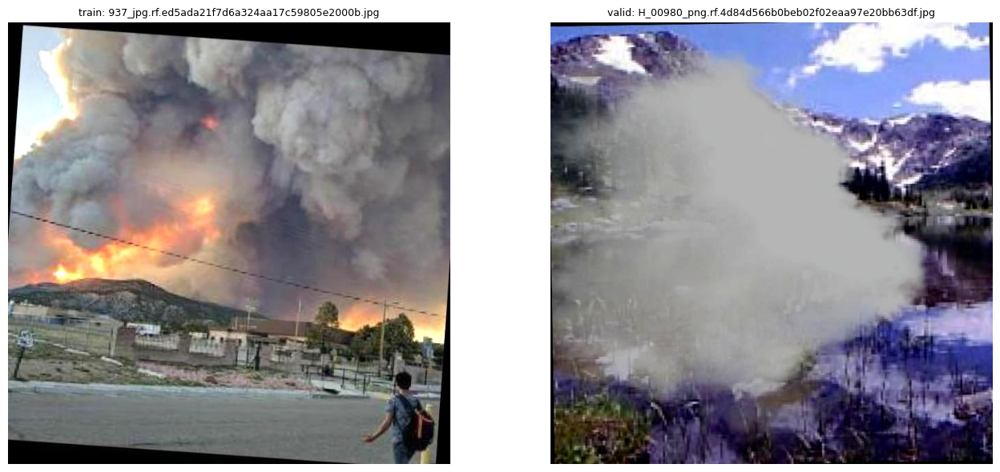

In [ ]:
import matplotlib.pyplot as plt

# Display images with empty labels for visual review.
review_images = [record["image"] for record in label_records]

fig, axes = plt.subplots(
    1,
    len(review_images),
    figsize=(7 * len(review_images), 6),
    squeeze=False,
)

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for axis, image_path in zip(axes[0], review_images):
        with Image.open(
            io.BytesIO(archive.read(image_path))
        ) as image:
            axis.imshow(image.convert("RGB"))

        split = image_path.split("/")[0]
        axis.set_title(f"{split}: {Path(image_path).name}", fontsize=9)
        axis.axis("off")

plt.tight_layout()
plt.show()

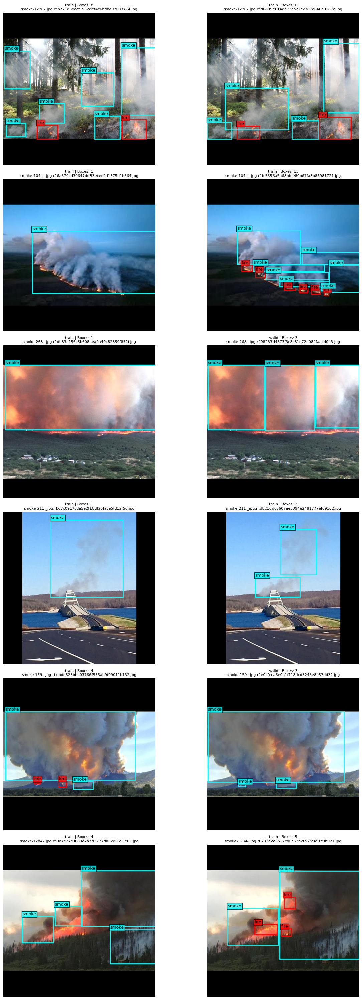

Box colors: fire = red, smoke = cyan
Sample figure saved to: /content/dataset_audit/annotation_conflict_samples.png
Sample paths saved to: /content/dataset_audit/sampled_annotation_conflicts.json


In [ ]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Select a reproducible sample of conflicting duplicate groups.
SAMPLE_SEED = 42
SAMPLE_SIZE = min(6, len(annotation_conflicts))

assert SAMPLE_SIZE > 0, "No annotation conflicts are available."

sampled_conflicts = random.Random(SAMPLE_SEED).sample(
    annotation_conflicts,
    SAMPLE_SIZE,
)

CLASS_COLORS = {
    0: "red",
    1: "cyan",
}


def display_annotations(axis, archive, image_path):
    """Display an image with its original YOLO annotations."""

    split = image_path.split("/")[0]
    label_path = f"{split}/labels/{Path(image_path).stem}.txt"

    # Load the image without changing the source archive.
    with Image.open(io.BytesIO(archive.read(image_path))) as image:
        rgb_image = image.convert("RGB")

    image_width, image_height = rgb_image.size
    axis.imshow(rgb_image)

    # Read all annotation rows, including repeated boxes.
    text = archive.read(label_path).decode("utf-8-sig")
    annotation_rows = [
        line.split()
        for line in text.splitlines()
        if line.strip()
    ]

    for row in annotation_rows:
        class_id, x, y, width, height = map(float, row)
        class_id = int(class_id)

        # Convert normalized YOLO coordinates to pixel coordinates.
        box_width = width * image_width
        box_height = height * image_height
        left = (x - width / 2) * image_width
        top = (y - height / 2) * image_height

        color = CLASS_COLORS[class_id]

        axis.add_patch(
            Rectangle(
                (left, top),
                box_width,
                box_height,
                linewidth=2,
                edgecolor=color,
                facecolor="none",
            )
        )

        axis.text(
            left,
            max(top - 4, 0),
            CLASS_NAMES[class_id],
            color="black",
            fontsize=9,
            bbox={
                "facecolor": color,
                "alpha": 0.8,
                "pad": 2,
            },
        )

    # Show the split and annotation count above each image.
    axis.set_title(
        f"{split} | Boxes: {len(annotation_rows)}\n"
        f"{Path(image_path).name}",
        fontsize=8,
    )
    axis.axis("off")


# Allow enough columns to show every image in each sampled group.
column_count = max(
    len(group["paths"])
    for group in sampled_conflicts
)

fig, axes = plt.subplots(
    SAMPLE_SIZE,
    column_count,
    figsize=(7 * column_count, 5 * SAMPLE_SIZE),
    squeeze=False,
)

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for row_index, group in enumerate(sampled_conflicts):
        for column_index, image_path in enumerate(group["paths"]):
            display_annotations(
                axes[row_index, column_index],
                archive,
                image_path,
            )

        # Hide unused panels if group sizes differ.
        for column_index in range(len(group["paths"]), column_count):
            axes[row_index, column_index].axis("off")

plt.tight_layout()

# Save the sample figure and the image paths for later reference.
figure_path = OUTPUT_DIR / "annotation_conflict_samples.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")

sample_path = OUTPUT_DIR / "sampled_annotation_conflicts.json"
sample_path.write_text(
    json.dumps(sampled_conflicts, indent=2),
    encoding="utf-8",
)

plt.show()

print("Box colors: fire = red, smoke = cyan")
print(f"Sample figure saved to: {figure_path}")
print(f"Sample paths saved to: {sample_path}")

In [ ]:
# Propose one retained image per exact duplicate group.
# This cell creates a review plan only. It does not modify the dataset.

SPLIT_PRIORITY = {
    "test": 0,
    "valid": 1,
    "train": 2,
}

# Identify duplicate groups with conflicting annotations.
conflicting_path_sets = {
    frozenset(item["paths"])
    for item in annotation_conflicts
}

removal_plan = []
retained_duplicate_paths = set()

for group in exact_groups:
    # Prefer test, then validation, then training.
    # Within the same split, use the filename as a deterministic tie-breaker.
    ordered_paths = sorted(
        group["paths"],
        key=lambda path: (
            SPLIT_PRIORITY[path.split("/")[0]],
            path,
        ),
    )

    retained_path = ordered_paths[0]
    retained_duplicate_paths.add(retained_path)

    annotation_review_required = (
        frozenset(group["paths"]) in conflicting_path_sets
    )

    for excluded_path in ordered_paths[1:]:
        removal_plan.append({
            "retained_image": retained_path,
            "excluded_image": excluded_path,
            "excluded_split": excluded_path.split("/")[0],
            "cross_split": group["cross_split"],
            "annotation_review_required": annotation_review_required,
            "reason": "Exact decoded-pixel duplicate",
        })

# Confirm that no image is proposed for exclusion more than once.
excluded_paths = {
    item["excluded_image"]
    for item in removal_plan
}

assert len(excluded_paths) == len(removal_plan), (
    "An image appears more than once in the exclusion plan."
)

assert retained_duplicate_paths.isdisjoint(excluded_paths), (
    "A retained image also appears in the exclusion plan."
)

# Count proposed exclusions for each split.
excluded_counts = collections.Counter(
    item["excluded_split"]
    for item in removal_plan
)

print("PROPOSED IMAGE COUNTS")
print(f"{'Split':<12}{'Original':>12}{'Excluded':>12}{'Remaining':>12}")

total_original = 0
total_remaining = 0

for split in SPLITS:
    original = split_summary[split]["images"]
    excluded = excluded_counts[split]
    remaining = original - excluded

    total_original += original
    total_remaining += remaining

    print(
        f"{split:<12}{original:>12,}"
        f"{excluded:>12,}{remaining:>12,}"
    )

print(
    f"{'Total':<12}{total_original:>12,}"
    f"{len(excluded_paths):>12,}{total_remaining:>12,}"
)

# Save the proposed plan for review and documentation.
plan_path = OUTPUT_DIR / "proposed_duplicate_exclusions.csv"

with plan_path.open(
    "w", newline="", encoding="utf-8-sig"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "retained_image",
            "excluded_image",
            "excluded_split",
            "cross_split",
            "annotation_review_required",
            "reason",
        ],
    )
    writer.writeheader()
    writer.writerows(removal_plan)

print(f"\nPlan saved to: {plan_path}")
print("No source images or labels were modified.")
print("Annotation conflicts and empty labels still require review.")
print("Visual near-duplicates are not covered by this plan.")

PROPOSED IMAGE COUNTS
Split           Original    Excluded   Remaining
train              8,826       1,120       7,706
valid              1,088          35       1,053
test               1,107          14       1,093
Total             11,021       1,169       9,852

Plan saved to: /content/dataset_audit/proposed_duplicate_exclusions.csv
No source images or labels were modified.
Annotation conflicts and empty labels still require review.
Visual near-duplicates are not covered by this plan.


In [ ]:
# Check whether empty-label images have exact duplicate copies.
# Existing annotations on a duplicate are review candidates,
# not automatically verified ground truth.

empty_image_paths = [
    record["image"] for record in label_records
]

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for image_path in empty_image_paths:
        matching_group = next(
            (
                group
                for group in exact_groups
                if image_path in group["paths"]
            ),
            None,
        )

        print(f"\nEmpty-label image: {image_path}")
        print(
            "Proposed action: "
            + (
                "Exclude as an exact duplicate"
                if image_path in excluded_paths
                else "Retain pending annotation review"
            )
        )

        if matching_group is None:
            print("No exact duplicate copy was found.")
            continue

        for duplicate_path in matching_group["paths"]:
            if duplicate_path == image_path:
                continue

            # Display the duplicate's label content for inspection.
            split = duplicate_path.split("/")[0]
            label_path = (
                f"{split}/labels/{Path(duplicate_path).stem}.txt"
            )

            label_text = archive.read(label_path).decode("utf-8-sig")
            box_count = sum(
                bool(line.strip())
                for line in label_text.splitlines()
            )

            print(f"Duplicate copy: {duplicate_path}")
            print(f"Annotation rows: {box_count}")
            print(label_text.strip() or "[Empty label]")

print("\nNo source files were modified.")


Empty-label image: train/images/937_jpg.rf.ed5ada21f7d6a324aa17c59805e2000b.jpg
Proposed action: Retain pending annotation review
No exact duplicate copy was found.

Empty-label image: valid/images/H_00980_png.rf.4d84d566b0beb02f02eaa97e20bb63df.jpg
Proposed action: Retain pending annotation review
No exact duplicate copy was found.

No source files were modified.


In [ ]:
import shutil

# Create a separate review copy without modifying the original archive.
REVIEW_ROOT = Path("/content/fire_smoke_review")
DATASET_DIR = REVIEW_ROOT / "dataset"
QUARANTINE_DIR = REVIEW_ROOT / "quarantine"
REPORTS_DIR = REVIEW_ROOT / "reports"

assert not REVIEW_ROOT.exists(), (
    "The review directory already exists. "
    "Use a new directory name to avoid mixing outputs."
)

# Quarantine both empty-label images pending manual review.
quarantine_paths = {
    record["image"] for record in label_records
}

all_image_paths = {
    record["image"] for record in image_records
}

assert excluded_paths <= all_image_paths
assert quarantine_paths <= all_image_paths

retained_paths = (
    all_image_paths - excluded_paths - quarantine_paths
)

# Confirm the expected counts before writing the review copy.
assert len(retained_paths) == 9850, (
    f"Unexpected retained image count: {len(retained_paths)}"
)

REPORTS_DIR.mkdir(parents=True)

change_log = []

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for image_path in sorted(all_image_paths):
        split = image_path.split("/")[0]
        label_path = (
            f"{split}/labels/{Path(image_path).stem}.txt"
        )

        if image_path in quarantine_paths:
            destination = QUARANTINE_DIR
            action = "quarantine"
            reason = "Empty label pending manual review"

        elif image_path in excluded_paths:
            # Excluded duplicates remain available in the original archive.
            change_log.append({
                "image": image_path,
                "action": "exclude_duplicate",
                "reason": "Exact duplicate according to the saved plan",
            })
            continue

        else:
            destination = DATASET_DIR
            action = "retain"
            reason = "Retained by the review plan"

        # Preserve each image and its original label without relabeling.
        for source_path in (image_path, label_path):
            target_path = destination / source_path
            target_path.parent.mkdir(parents=True, exist_ok=True)
            target_path.write_bytes(archive.read(source_path))

        change_log.append({
            "image": image_path,
            "action": action,
            "reason": reason,
        })

# Write dataset paths relative to this configuration file.
config_text = (
    "train: train/images\n"
    "val: valid/images\n"
    "test: test/images\n"
    "nc: 2\n"
    "names: ['fire', 'smoke']\n"
)

(DATASET_DIR / "data.yaml").write_text(
    config_text,
    encoding="utf-8",
)

# Preserve the audit reports generated so far.
for source_path in OUTPUT_DIR.iterdir():
    if source_path.is_file():
        shutil.copy2(source_path, REPORTS_DIR / source_path.name)

# Save a complete record of retained, excluded, and quarantined images.
with (REPORTS_DIR / "change_log.csv").open(
    "w", newline="", encoding="utf-8-sig"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["image", "action", "reason"],
    )
    writer.writeheader()
    writer.writerows(change_log)

# Record limitations so the review copy is not mistaken for final data.
(REVIEW_ROOT / "REVIEW_STATUS.txt").write_text(
    "Status: Review copy, not final training data.\n"
    "Exact duplicate images were excluded using the recorded plan.\n"
    "Two empty-label images were quarantined for manual review.\n"
    "Retained annotations were copied without modification.\n"
    "Annotation conflicts and duplicate boxes remain unresolved.\n"
    "Visual near-duplicate review remains pending.\n"
    "The original dataset archive was not modified.\n",
    encoding="utf-8",
)

print(f"Review copy created: {REVIEW_ROOT}")
print("The original dataset archive was not modified.")

Review copy created: /content/fire_smoke_review
The original dataset archive was not modified.


In [ ]:
# Verify actual output files rather than relying only on planned counts.
expected_counts = {
    "train": 7705,
    "valid": 1052,
    "test": 1093,
}

verified_hashes = set()

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for split, expected_count in expected_counts.items():
        images = sorted((DATASET_DIR / split / "images").glob("*"))
        labels = sorted((DATASET_DIR / split / "labels").glob("*.txt"))

        assert len(images) == expected_count, (
            f"Unexpected image count in {split}"
        )
        assert len(labels) == expected_count, (
            f"Unexpected label count in {split}"
        )

        for image_path in images:
            relative_image = image_path.relative_to(
                DATASET_DIR
            ).as_posix()

            label_path = (
                DATASET_DIR / split / "labels"
                / f"{image_path.stem}.txt"
            )
            relative_label = label_path.relative_to(
                DATASET_DIR
            ).as_posix()

            # Confirm image-label pairing and unchanged source content.
            assert label_path.is_file()
            assert image_path.read_bytes() == archive.read(relative_image)
            assert label_path.read_bytes() == archive.read(relative_label)

            # Confirm no exact decoded-pixel duplicates remain.
            with Image.open(image_path) as image:
                rgb_image = image.convert("RGB")
                fingerprint = hashlib.sha256(
                    str(rgb_image.size).encode("utf-8")
                    + rgb_image.tobytes()
                ).hexdigest()

            assert fingerprint not in verified_hashes, (
                f"Remaining exact duplicate: {relative_image}"
            )
            verified_hashes.add(fingerprint)

        print(
            f"{split}: {len(images):,} images, "
            f"{len(labels):,} labels — verified"
        )

print(f"\nTotal retained images: {len(verified_hashes):,}")
print("Exact duplicate check passed across all splits.")
print("Annotation review is still required before training.")

train: 7,705 images, 7,705 labels — verified
valid: 1,052 images, 1,052 labels — verified
test: 1,093 images, 1,093 labels — verified

Total retained images: 9,850
Exact duplicate check passed across all splits.
Annotation review is still required before training.


In [ ]:
# Remove repeated identical annotation rows from the review copy only.
# Preserve a backup of every changed label and record each change.

label_cleanup_log = []
BACKUP_DIR = REPORTS_DIR / "labels_before_box_deduplication"

for split in SPLITS:
    label_directory = DATASET_DIR / split / "labels"

    for label_path in sorted(label_directory.glob("*.txt")):
        original_text = label_path.read_text(encoding="utf-8-sig")
        original_rows = [
            line for line in original_text.splitlines()
            if line.strip()
        ]

        seen_annotations = set()
        retained_rows = []
        removed_count = 0

        for row in original_rows:
            # Compare numeric values while preserving the original row text.
            signature = tuple(float(value) for value in row.split())

            if signature in seen_annotations:
                removed_count += 1
                continue

            seen_annotations.add(signature)
            retained_rows.append(row)

        if removed_count == 0:
            continue

        relative_path = label_path.relative_to(DATASET_DIR)

        # Back up the original label before changing the review copy.
        backup_path = BACKUP_DIR / relative_path
        backup_path.parent.mkdir(parents=True, exist_ok=True)
        assert not backup_path.exists(), (
            f"A backup already exists: {backup_path}"
        )
        shutil.copy2(label_path, backup_path)

        label_path.write_text(
            "\n".join(retained_rows) + "\n",
            encoding="utf-8",
        )

        label_cleanup_log.append({
            "label": relative_path.as_posix(),
            "original_boxes": len(original_rows),
            "removed_duplicate_boxes": removed_count,
            "remaining_boxes": len(retained_rows),
        })

# Save a separate log without replacing earlier audit reports.
cleanup_log_path = REPORTS_DIR / "duplicate_box_cleanup.json"

if label_cleanup_log:
    assert not cleanup_log_path.exists(), (
        "A cleanup log already exists. Preserve it before continuing."
    )
    cleanup_log_path.write_text(
        json.dumps(label_cleanup_log, indent=2),
        encoding="utf-8",
    )

# Verify that no repeated annotation rows remain.
for split in SPLITS:
    for label_path in (DATASET_DIR / split / "labels").glob("*.txt"):
        signatures = [
            tuple(float(value) for value in line.split())
            for line in label_path.read_text(
                encoding="utf-8-sig"
            ).splitlines()
            if line.strip()
        ]
        assert len(signatures) == len(set(signatures)), (
            f"Repeated annotation remains: {label_path}"
        )

print(f"Changed label files: {len(label_cleanup_log)}")
print(
    "Removed duplicate annotation rows: "
    f"{sum(item['removed_duplicate_boxes'] for item in label_cleanup_log)}"
)
print("Duplicate annotation check passed.")
print("Image counts are unchanged: 9,850.")
print("The original dataset archive was not modified.")

Changed label files: 2
Removed duplicate annotation rows: 2
Duplicate annotation check passed.
Image counts are unchanged: 9,850.
The original dataset archive was not modified.


In [ ]:
import shutil
from pathlib import Path
from google.colab import files

# Confirm that the review copy exists.
REVIEW_ROOT = Path("/content/fire_smoke_review")
assert REVIEW_ROOT.is_dir(), "The review directory was not found."

# Package the dataset, quarantine folder, and reports together.
archive_path = shutil.make_archive(
    base_name="/content/fire_smoke_review_backup",
    format="zip",
    root_dir=REVIEW_ROOT.parent,
    base_dir=REVIEW_ROOT.name,
)

print(f"Backup created: {archive_path}")

# Download the backup to your computer.
files.download(archive_path)

Backup created: /content/fire_smoke_review_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Categorize annotation conflicts to prioritize manual review.
# These categories describe differences; they do not determine correctness.

def read_annotation_rows(archive, image_path):
    """Read unique YOLO annotation rows from the original archive."""
    split = image_path.split("/")[0]
    label_path = f"{split}/labels/{Path(image_path).stem}.txt"

    text = archive.read(label_path).decode("utf-8-sig")

    return {
        tuple(float(value) for value in line.split())
        for line in text.splitlines()
        if line.strip()
    }


conflict_review_queue = []

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for group in annotation_conflicts:
        paths = sorted(group["paths"])

        # Find the image actually retained in the review copy.
        retained_candidates = [
            path for path in paths
            if (DATASET_DIR / path).is_file()
        ]

        assert len(retained_candidates) == 1, (
            f"Expected one retained image for group: {paths}"
        )

        annotations = [
            read_annotation_rows(archive, path)
            for path in paths
        ]

        # Compare the classes present in each version.
        class_sets = [
            frozenset(int(row[0]) for row in rows)
            for rows in annotations
        ]

        # Compare unique box counts separately for each class.
        class_count_signatures = [
            tuple(
                sum(int(row[0]) == class_id for row in rows)
                for class_id in sorted(CLASS_NAMES)
            )
            for rows in annotations
        ]

        if len(set(class_sets)) > 1:
            category = "different_class_presence"
            priority = 1
        elif len(set(class_count_signatures)) > 1:
            category = "different_box_counts"
            priority = 2
        else:
            category = "different_box_coordinates"
            priority = 3

        conflict_review_queue.append({
            "priority": priority,
            "category": category,
            "retained_image": retained_candidates[0],
            "original_versions": paths,
            "unique_boxes_per_version": [
                len(rows) for rows in annotations
            ],
            "status": "pending",
        })

# Sort the queue reproducibly.
conflict_review_queue.sort(
    key=lambda item: (
        item["priority"],
        item["retained_image"],
    )
)

category_counts = collections.Counter(
    item["category"] for item in conflict_review_queue
)

print("ANNOTATION REVIEW QUEUE")

for category in (
    "different_class_presence",
    "different_box_counts",
    "different_box_coordinates",
):
    print(f"{category}: {category_counts[category]:,} groups")

print(f"\nTotal groups requiring review: {len(conflict_review_queue):,}")

# Save the queue with the other review-copy reports.
queue_path = REPORTS_DIR / "annotation_review_queue.json"

queue_path.write_text(
    json.dumps(conflict_review_queue, indent=2),
    encoding="utf-8",
)

print(f"Review queue saved to: {queue_path}")
print("No images or annotations were modified.")

ANNOTATION REVIEW QUEUE
different_class_presence: 228 groups
different_box_counts: 550 groups
different_box_coordinates: 378 groups

Total groups requiring review: 1,156
Review queue saved to: /content/fire_smoke_review/reports/annotation_review_queue.json
No images or annotations were modified.


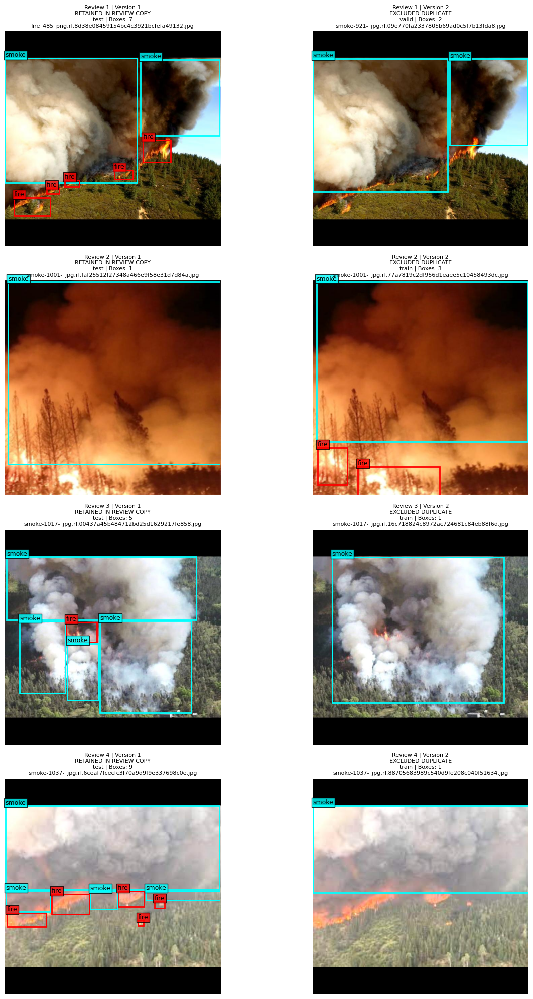

Box colors: fire = red, smoke = cyan
RETAINED indicates the current copy, not verified annotation quality.
No annotation changes were made.


In [ ]:
# Review class-presence conflicts in small, reproducible batches.
# Change BATCH_START to 4, 8, 12, etc. to view later batches.

BATCH_START = 0
BATCH_SIZE = 4

class_conflicts = [
    item
    for item in conflict_review_queue
    if item["category"] == "different_class_presence"
]

review_batch = class_conflicts[
    BATCH_START:BATCH_START + BATCH_SIZE
]

assert review_batch, "No review items are available at this batch position."

column_count = max(
    len(item["original_versions"])
    for item in review_batch
)

fig, axes = plt.subplots(
    len(review_batch),
    column_count,
    figsize=(7 * column_count, 5 * len(review_batch)),
    squeeze=False,
)

with zipfile.ZipFile(DATASET_ZIP) as archive:
    for row_index, item in enumerate(review_batch):
        review_number = BATCH_START + row_index + 1

        for column_index, image_path in enumerate(
            item["original_versions"]
        ):
            axis = axes[row_index, column_index]

            # Display original annotations for comparison.
            display_annotations(axis, archive, image_path)

            # Mark which version exists in the current review copy.
            is_retained = image_path == item["retained_image"]
            status = (
                "RETAINED IN REVIEW COPY"
                if is_retained
                else "EXCLUDED DUPLICATE"
            )

            original_title = axis.get_title()
            axis.set_title(
                f"Review {review_number} | Version {column_index + 1}\n"
                f"{status}\n{original_title}",
                fontsize=8,
            )

        # Hide unused panels if duplicate groups have different sizes.
        for column_index in range(
            len(item["original_versions"]), column_count
        ):
            axes[row_index, column_index].axis("off")

plt.tight_layout()

# Save the displayed batch and its source paths for documentation.
batch_name = f"class_conflicts_{BATCH_START + 1:03d}"

fig.savefig(
    REPORTS_DIR / f"{batch_name}.png",
    dpi=150,
    bbox_inches="tight",
)

(REPORTS_DIR / f"{batch_name}.json").write_text(
    json.dumps(review_batch, indent=2),
    encoding="utf-8",
)

plt.show()

print("Box colors: fire = red, smoke = cyan")
print("RETAINED indicates the current copy, not verified annotation quality.")
print("No annotation changes were made.")

In [ ]:
%pip -q install ImageHash

In [ ]:
import imagehash

# Record the four displayed groups as an illustrative review sample.
# These observations do not approve either annotation version.
sample_notes = [
    "The retained version includes fire labels missing from the other version.",
    "Visible fire is not labeled in the retained version.",
    "The retained version includes a fire label missing from the other version.",
    "The retained version includes fire labels missing from the other version.",
]

sample_review_log = []

for item, note in zip(class_conflicts[:4], sample_notes):
    sample_review_log.append({
        "retained_image": item["retained_image"],
        "original_versions": item["original_versions"],
        "observation": note,
        "annotation_action": "No changes made",
        "review_status": "Preliminary visual observation",
    })

(REPORTS_DIR / "illustrative_annotation_review.json").write_text(
    json.dumps(sample_review_log, indent=2),
    encoding="utf-8",
)

# Compute a perceptual fingerprint for each retained image.
# Unlike exact hashes, perceptual hashes can identify similar images.
perceptual_records = []

for index, record in enumerate(image_records, start=1):
    image_path = DATASET_DIR / record["image"]

    if not image_path.is_file():
        continue

    with Image.open(image_path) as image:
        fingerprint = imagehash.phash(
            image.convert("RGB"),
            hash_size=8,
        )

    perceptual_records.append({
        "image": record["image"],
        "split": record["split"],
        "phash": str(fingerprint),
    })

    if len(perceptual_records) % 1000 == 0:
        print(f"Fingerprints computed: {len(perceptual_records):,}")

assert len(perceptual_records) == 9850, (
    "Unexpected number of retained images."
)

(REPORTS_DIR / "perceptual_hashes.json").write_text(
    json.dumps(perceptual_records, indent=2),
    encoding="utf-8",
)

print(f"Completed: {len(perceptual_records):,} fingerprints")
print("The four illustrative review groups were documented.")
print("No images or annotations were modified.")

Fingerprints computed: 1,000
Fingerprints computed: 2,000
Fingerprints computed: 3,000
Fingerprints computed: 4,000
Fingerprints computed: 5,000
Fingerprints computed: 6,000
Fingerprints computed: 7,000
Fingerprints computed: 8,000
Fingerprints computed: 9,000
Completed: 9,850 fingerprints
The four illustrative review groups were documented.
No images or annotations were modified.


In [ ]:
import numpy as np
from itertools import combinations

# A smaller Hamming distance means more similar perceptual fingerprints.
# This threshold selects candidates only; it does not prove duplication.
MAX_HASH_DISTANCE = 4

split_records = {
    split: [
        record for record in perceptual_records
        if record["split"] == split
    ]
    for split in SPLITS
}

# Store each 64-bit fingerprint as eight bytes.
def hash_bytes(records):
    return np.array(
        [
            list(bytes.fromhex(record["phash"]))
            for record in records
        ],
        dtype=np.uint8,
    ).reshape(-1, 8)


# Precompute the number of set bits for each possible byte value.
bit_counts = np.array(
    [value.bit_count() for value in range(256)],
    dtype=np.uint8,
)

similarity_candidates = []

for split_a, split_b in combinations(SPLITS, 2):
    records_a = split_records[split_a]
    records_b = split_records[split_b]
    hashes_b = hash_bytes(records_b)

    for record_a in records_a:
        hash_a = np.frombuffer(
            bytes.fromhex(record_a["phash"]),
            dtype=np.uint8,
        )

        # Compare this image with all images in the other split.
        distances = bit_counts[
            np.bitwise_xor(hashes_b, hash_a)
        ].sum(axis=1)

        for match_index in np.flatnonzero(
            distances <= MAX_HASH_DISTANCE
        ):
            record_b = records_b[int(match_index)]

            similarity_candidates.append({
                "image_a": record_a["image"],
                "image_b": record_b["image"],
                "hash_distance": int(distances[match_index]),
                "status": "Pending visual review",
            })

    print(f"Compared: {split_a} + {split_b}")

similarity_candidates.sort(
    key=lambda item: (
        item["hash_distance"],
        item["image_a"],
        item["image_b"],
    )
)

candidate_path = REPORTS_DIR / "cross_split_similarity_candidates.json"
candidate_path.write_text(
    json.dumps(similarity_candidates, indent=2),
    encoding="utf-8",
)

print(f"\nCandidate pairs: {len(similarity_candidates):,}")
print(f"Report saved to: {candidate_path}")
print("Similar images have not been removed.")

Compared: train + valid
Compared: train + test
Compared: valid + test

Candidate pairs: 4,690
Report saved to: /content/fire_smoke_review/reports/cross_split_similarity_candidates.json
Similar images have not been removed.


CANDIDATE PAIRS BY HASH DISTANCE
Distance 0: 1,567 pairs
Distance 2: 1,680 pairs
Distance 4: 1,443 pairs

Unique images appearing in candidate pairs: 2,770


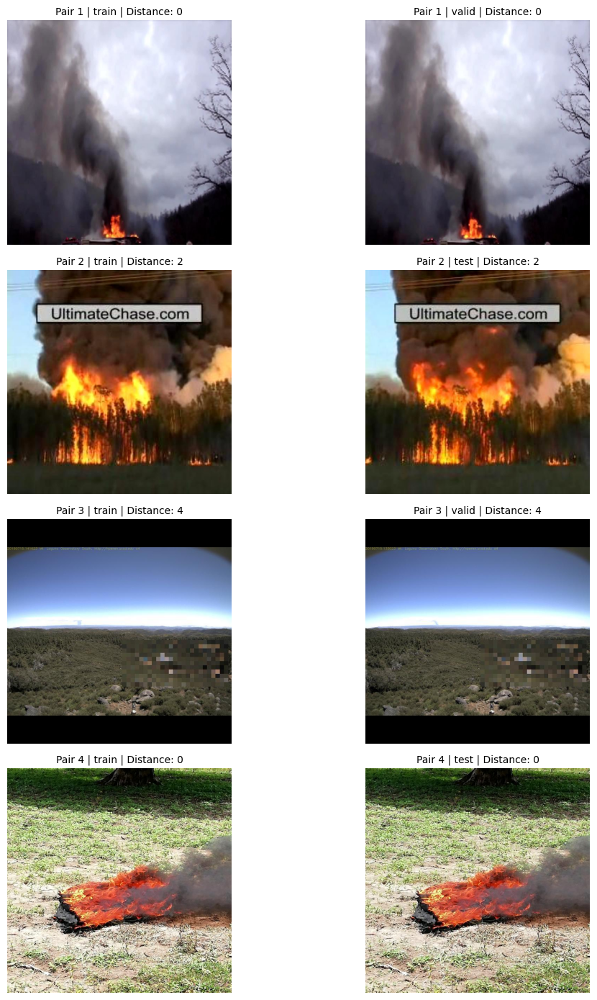

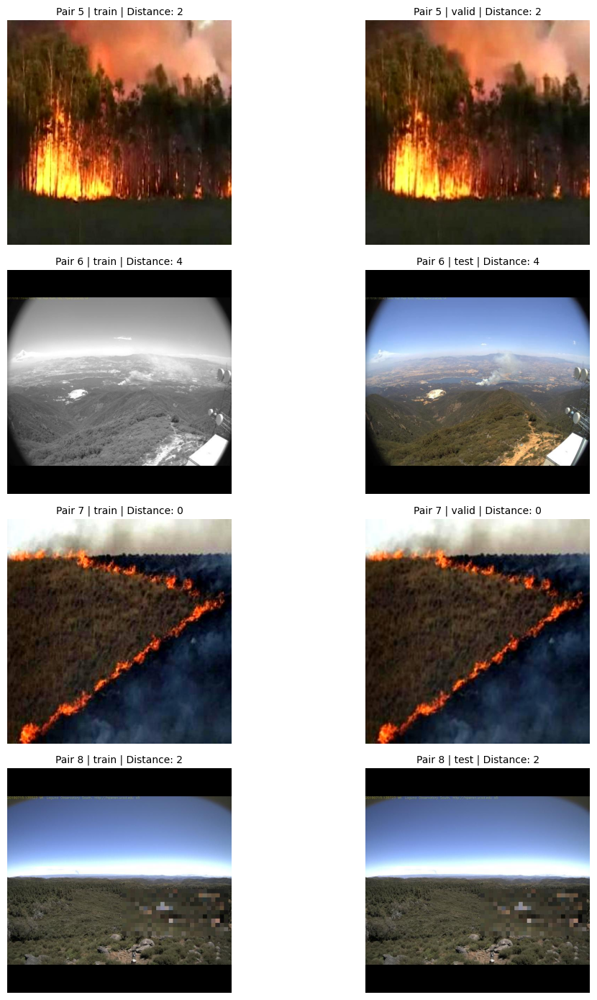

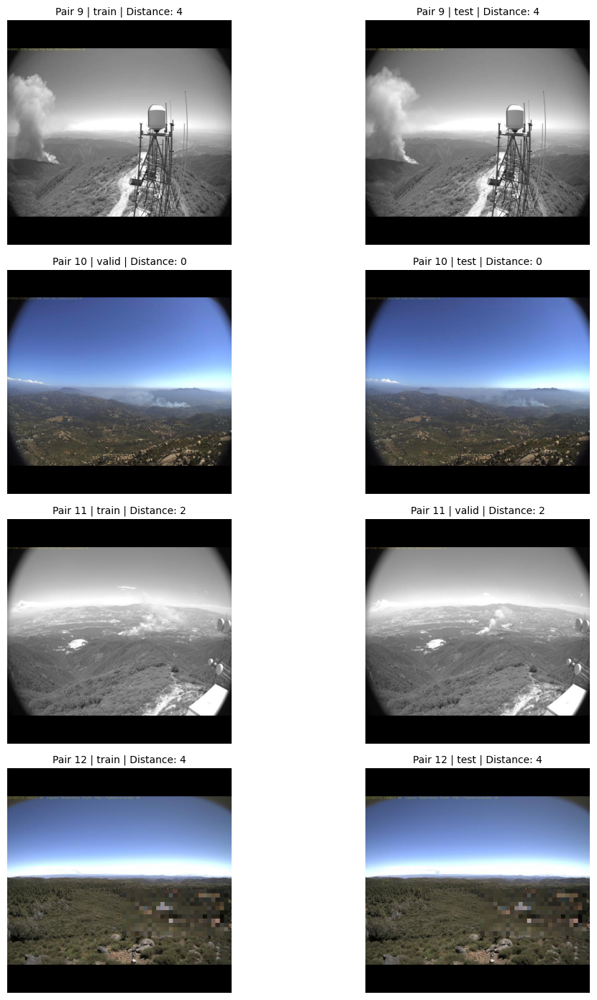

This is an exploratory sample, not a complete similarity review.
No images or annotations were modified.


In [ ]:
import random
import matplotlib.pyplot as plt

# Summarize candidate pairs by perceptual-hash distance.
distance_counts = collections.Counter(
    item["hash_distance"]
    for item in similarity_candidates
)

print("CANDIDATE PAIRS BY HASH DISTANCE")
for distance, count in sorted(distance_counts.items()):
    print(f"Distance {distance}: {count:,} pairs")

unique_candidate_images = {
    item[key]
    for item in similarity_candidates
    for key in ("image_a", "image_b")
}

print(
    f"\nUnique images appearing in candidate pairs: "
    f"{len(unique_candidate_images):,}"
)

# Sample across distance levels instead of showing only the closest pairs.
rng = random.Random(42)
sampled_pairs = []
used_images = set()

distance_levels = sorted(distance_counts)
target_pairs = min(12, len(similarity_candidates))

pools = {}
for distance in distance_levels:
    pool = [
        item for item in similarity_candidates
        if item["hash_distance"] == distance
    ]
    rng.shuffle(pool)
    pools[distance] = pool

# Prefer pairs that do not repeat images already shown in the panel.
while len(sampled_pairs) < target_pairs:
    added_pair = False

    for distance in distance_levels:
        while pools[distance]:
            candidate = pools[distance].pop()

            if (
                candidate["image_a"] in used_images
                or candidate["image_b"] in used_images
            ):
                continue

            sampled_pairs.append(candidate)
            used_images.update([
                candidate["image_a"],
                candidate["image_b"],
            ])
            added_pair = True
            break

        if len(sampled_pairs) == target_pairs:
            break

    if not added_pair:
        break

assert sampled_pairs, "No candidate pairs are available for display."

# Show four pairs per figure for readable screenshots.
for batch_start in range(0, len(sampled_pairs), 4):
    batch = sampled_pairs[batch_start:batch_start + 4]

    fig, axes = plt.subplots(
        len(batch),
        2,
        figsize=(12, 3.5 * len(batch)),
        squeeze=False,
    )

    for row_index, pair in enumerate(batch):
        pair_number = batch_start + row_index + 1

        for column_index, key in enumerate(("image_a", "image_b")):
            relative_path = pair[key]
            image_path = DATASET_DIR / relative_path

            # Display original pixels without annotation overlays.
            with Image.open(image_path) as image:
                axes[row_index, column_index].imshow(
                    image.convert("RGB")
                )

            split = relative_path.split("/")[0]
            axes[row_index, column_index].set_title(
                f"Pair {pair_number} | {split} | "
                f"Distance: {pair['hash_distance']}",
                fontsize=10,
            )
            axes[row_index, column_index].axis("off")

    plt.tight_layout()

    fig.savefig(
        REPORTS_DIR / f"similarity_sample_{batch_start + 1:02d}.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

# Save the displayed paths to make the sample reproducible.
(REPORTS_DIR / "similarity_review_sample.json").write_text(
    json.dumps(sampled_pairs, indent=2),
    encoding="utf-8",
)

print("This is an exploratory sample, not a complete similarity review.")
print("No images or annotations were modified.")

In [ ]:
import collections
import json
from pathlib import Path

REPORTS_DIR = Path("/content/fire_smoke_review/reports")
DATASET_DIR = Path("/content/fire_smoke_review/dataset")

# Load saved candidate pairs if they are not already in memory.
if "similarity_candidates" not in globals():
    candidate_path = (
        REPORTS_DIR / "cross_split_similarity_candidates.json"
    )

    assert candidate_path.is_file(), (
        "The similarity report was not found. "
        "Restore the review backup or rerun the similarity scan."
    )

    similarity_candidates = json.loads(
        candidate_path.read_text(encoding="utf-8")
    )

assert similarity_candidates, "No similarity candidates were found."

# Build connected groups from the candidate pairs.
parent = {}


def find(image_path):
    """Find the representative of a connected group."""
    parent.setdefault(image_path, image_path)

    while parent[image_path] != image_path:
        parent[image_path] = parent[parent[image_path]]
        image_path = parent[image_path]

    return image_path


def union(image_a, image_b):
    """Connect two candidate images."""
    root_a = find(image_a)
    root_b = find(image_b)

    if root_a != root_b:
        parent[root_b] = root_a


for pair in similarity_candidates:
    union(pair["image_a"], pair["image_b"])

components = collections.defaultdict(list)

for image_path in sorted(parent):
    components[find(image_path)].append(image_path)

# Assign reproducible group IDs, starting with the largest groups.
ordered_components = sorted(
    components.values(),
    key=lambda paths: (-len(paths), min(paths)),
)

similarity_groups = []

for index, paths in enumerate(ordered_components, start=1):
    split_counts = collections.Counter(
        path.split("/")[0] for path in paths
    )

    similarity_groups.append({
        "group_id": f"SG{index:04d}",
        "image_count": len(paths),
        "split_counts": dict(split_counts),
        "images": sorted(paths),
        "status": "Pending visual review",
    })

# Save the groups for reuse.
(REPORTS_DIR / "similarity_groups.json").write_text(
    json.dumps(similarity_groups, indent=2),
    encoding="utf-8",
)

print(f"Candidate groups created: {len(similarity_groups):,}")
print(
    "Images in candidate groups: "
    f"{sum(group['image_count'] for group in similarity_groups):,}"
)
print("Ready to run the JPG export cell.")

Candidate groups created: 684
Images in candidate groups: 2,770
Ready to run the JPG export cell.


In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont, ImageOps
from google.colab import files

import csv
import math
import shutil

assert similarity_groups, "Run the similarity grouping cell first."

from uuid import uuid4

# Create a unique export directory for each run.
EXPORT_DIR = Path(
    f"/content/similarity_review_jpg_{uuid4().hex[:8]}"
)
EXPORT_DIR.mkdir(parents=True)

print(f"Export directory: {EXPORT_DIR}")

# Configure readable contact sheets.
COLUMNS = 3
ROWS_PER_PAGE = 4
IMAGES_PER_PAGE = COLUMNS * ROWS_PER_PAGE

CELL_WIDTH = 480
IMAGE_HEIGHT = 400
LABEL_HEIGHT = 76
HEADER_HEIGHT = 90
CELL_HEIGHT = IMAGE_HEIGHT + LABEL_HEIGHT

# Use a font available in Colab, with a fallback.
FONT_PATH = "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"

try:
    title_font = ImageFont.truetype(FONT_PATH, 25)
    label_font = ImageFont.truetype(FONT_PATH, 17)
except OSError:
    title_font = ImageFont.load_default()
    label_font = ImageFont.load_default()

manifest_rows = []
exported_images = set()
page_count = 0

for group_index, group in enumerate(similarity_groups, start=1):
    # Keep images from the same split together.
    image_paths = sorted(
        group["images"],
        key=lambda path: (
            SPLITS.index(path.split("/")[0]),
            path,
        ),
    )

    group_folder = EXPORT_DIR / group["group_id"]
    group_folder.mkdir()

    total_pages = math.ceil(len(image_paths) / IMAGES_PER_PAGE)

    for page_index in range(total_pages):
        start = page_index * IMAGES_PER_PAGE
        page_paths = image_paths[start:start + IMAGES_PER_PAGE]
        row_count = math.ceil(len(page_paths) / COLUMNS)


        sheet = Image.new( # Create a white canvas with both width and height.
            "RGB",
            (
                COLUMNS * CELL_WIDTH,
                HEADER_HEIGHT + row_count * CELL_HEIGHT,
            ),
            "white",
        )

                # Add the group ID and page number.
        draw = ImageDraw.Draw(sheet)
        draw.text(
            (15, 15),
            (
                f"{group['group_id']} | "
                f"Page {page_index + 1}/{total_pages} | "
                f"Group images: {len(image_paths)}"
            ),
            fill="black",
            font=title_font,
        )

        for panel_index, relative_path in enumerate(page_paths):
            image_number = start + panel_index + 1
            split = relative_path.split("/")[0]
            source_path = DATASET_DIR / relative_path

            x = (panel_index % COLUMNS) * CELL_WIDTH
            y = HEADER_HEIGHT + (panel_index // COLUMNS) * CELL_HEIGHT

            # Resize the full image without cropping.
            with Image.open(source_path) as source:
                thumbnail = ImageOps.contain(
                    source.convert("RGB"),
                    (CELL_WIDTH - 16, IMAGE_HEIGHT - 10),
                    method=Image.Resampling.LANCZOS,
                )

            image_x = x + (CELL_WIDTH - thumbnail.width) // 2
            image_y = y + (IMAGE_HEIGHT - thumbnail.height) // 2
            sheet.paste(thumbnail, (image_x, image_y))

            # Use the CSV to look up the full original filename.
            draw.text(
                (x + 10, y + IMAGE_HEIGHT + 5),
                f"Image {image_number:04d} | Split: {split}",
                fill="black",
                font=label_font,
            )
            draw.text(
                (x + 10, y + IMAGE_HEIGHT + 31),
                f"Group: {group['group_id']}",
                fill="black",
                font=label_font,
            )

            page_name = (
                f"{group['group_id']}_page_{page_index + 1:03d}.jpg"
            )

            manifest_rows.append({
                "group_id": group["group_id"],
                "page": page_index + 1,
                "image_number": image_number,
                "split": split,
                "image_path": relative_path,
                "contact_sheet": f"{group['group_id']}/{page_name}",
                "review_status": "Pending",
                "review_notes": "",
            })

            exported_images.add(relative_path)

        # Save the completed contact sheet.
        sheet.save(
            group_folder / page_name,
            format="JPEG",
            quality=95,
            subsampling=0,
        )
        page_count += 1

    if group_index % 25 == 0 or group_index == len(similarity_groups):
        print(
            f"Groups exported: {group_index:,}/"
            f"{len(similarity_groups):,}"
        )

# Verify that every image in the candidate groups was included.
expected_paths = {
    path
    for group in similarity_groups
    for path in group["images"]
}

assert exported_images == expected_paths, (
    "Some candidate images were not exported."
)

# Save a CSV linking each numbered panel to its original image.
manifest_path = EXPORT_DIR / "review_manifest.csv"

with manifest_path.open(
    "w", newline="", encoding="utf-8-sig"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "group_id",
            "page",
            "image_number",
            "split",
            "image_path",
            "contact_sheet",
            "review_status",
            "review_notes",
        ],
    )
    writer.writeheader()
    writer.writerows(manifest_rows)

# Include instructions for reviewing the JPG pages.
(EXPORT_DIR / "README.txt").write_text(
    "VISUAL SIMILARITY REVIEW\n\n"
    "Each group folder contains numbered JPG contact sheets.\n"
    "Review all pages before making a group-level decision.\n"
    "Use review_manifest.csv to identify each source image.\n"
    "Candidate groups are not confirmed duplicate scenes.\n"
    "Record observations in review_status and review_notes.\n"
    "Use original images when thumbnail details are insufficient.\n"
    "No source images, labels, or splits were modified.\n",
    encoding="utf-8",
)

# Create a uniquely named ZIP archive and download it.
zip_path = shutil.make_archive(
    base_name=str(EXPORT_DIR),
    format="zip",
    root_dir=EXPORT_DIR.parent,
    base_dir=EXPORT_DIR.name,
)

print(f"\nGroups exported: {len(similarity_groups):,}")
print(f"Images included: {len(exported_images):,}")
print(f"JPG pages created: {page_count:,}")
print(f"ZIP file: {zip_path}")

files.download(zip_path)

Export directory: /content/similarity_review_jpg_579c2a2e
Groups exported: 25/684
Groups exported: 50/684
Groups exported: 75/684
Groups exported: 100/684
Groups exported: 125/684
Groups exported: 150/684
Groups exported: 175/684
Groups exported: 200/684
Groups exported: 225/684
Groups exported: 250/684
Groups exported: 275/684
Groups exported: 300/684
Groups exported: 325/684
Groups exported: 350/684
Groups exported: 375/684
Groups exported: 400/684
Groups exported: 425/684
Groups exported: 450/684
Groups exported: 475/684
Groups exported: 500/684
Groups exported: 525/684
Groups exported: 550/684
Groups exported: 575/684
Groups exported: 600/684
Groups exported: 625/684
Groups exported: 650/684
Groups exported: 675/684
Groups exported: 684/684

Groups exported: 684
Images included: 2,770
JPG pages created: 728
ZIP file: /content/similarity_review_jpg_579c2a2e.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter

# Locate the candidate dataset archive.
CANDIDATE_ZIP = Path("/content/fire_smoke_grouped_candidate.zip")

assert CANDIDATE_ZIP.is_file(), (
    "Upload fire_smoke_grouped_candidate.zip to /content first."
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Count images by split without extracting or modifying the archive.
image_counts = Counter()

with ZipFile(CANDIDATE_ZIP) as archive:
    for member in archive.infolist():
        if member.is_dir():
            continue

        path = Path(member.filename)

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        for split in ("train", "valid", "test"):
            if f"dataset/{split}/images/" in path.as_posix():
                image_counts[split] += 1
                break

# Verify that the uploaded archive matches the candidate dataset.
expected_counts = {"train": 7876, "valid": 986, "test": 986}

assert dict(image_counts) == expected_counts, (
    f"Unexpected image counts: {dict(image_counts)}. "
    "Check that you uploaded the correct candidate archive."
)

print(f"Dataset: {CANDIDATE_ZIP.name}")
print()
for split in ("train", "valid", "test"):
    print(f"{split}: {image_counts[split]:,} images")

print(f"\nTotal: {sum(image_counts.values()):,} images")
print("Candidate image counts verified.")

Dataset: fire_smoke_grouped_candidate.zip

train: 7,876 images
valid: 986 images
test: 986 images

Total: 9,848 images
Candidate image counts verified.


In [ ]:
from collections import Counter
from pathlib import PurePosixPath
from zipfile import ZipFile

# Define the dataset splits and class names.
SPLITS = ("train", "valid", "test")
CLASS_NAMES = {0: "fire", 1: "smoke"}

# Store image-level and bounding-box-level counts separately.
class_stats = {
    split: {
        "labels": 0,
        "empty_labels": 0,
        "images": Counter(),
        "boxes": Counter(),
    }
    for split in SPLITS
}

with ZipFile(CANDIDATE_ZIP) as archive:
    # Confirm the class mapping recorded in the dataset configuration.
    yaml_files = [
        name for name in archive.namelist()
        if PurePosixPath(name).name == "data.yaml"
        and "dataset" in PurePosixPath(name).parts
    ]

    assert len(yaml_files) == 1, "Expected one dataset configuration file."

    print("Dataset configuration:")
    print(archive.read(yaml_files[0]).decode("utf-8-sig"))

    for member in archive.infolist():
        if member.is_dir():
            continue

        path = PurePosixPath(member.filename)

        if path.suffix.lower() != ".txt":
            continue

        # Only include labels from the candidate dataset.
        split = next(
            (
                split for split in SPLITS
                if f"dataset/{split}/labels/" in path.as_posix()
            ),
            None,
        )

        if split is None:
            continue

        stats = class_stats[split]
        stats["labels"] += 1
        present_classes = set()

        text = archive.read(member).decode("utf-8-sig")

        for line_number, line in enumerate(text.splitlines(), start=1):
            if not line.strip():
                continue

            # Read a YOLO detection annotation: class, x, y, width, height.
            values = line.split()
            assert len(values) == 5, (
                f"Unexpected annotation format: {path}, line {line_number}"
            )

            class_value = float(values[0])
            assert class_value.is_integer(), (
                f"Non-integer class ID: {path}, line {line_number}"
            )

            class_id = int(class_value)
            assert class_id in CLASS_NAMES, (
                f"Unknown class ID: {path}, line {line_number}"
            )

            stats["boxes"][class_id] += 1
            present_classes.add(class_id)

        # Count each image once per class, regardless of its box count.
        for class_id in present_classes:
            stats["images"][class_id] += 1

        if not present_classes:
            stats["empty_labels"] += 1

# Verify label counts against the previously checked image counts.
for split in SPLITS:
    assert class_stats[split]["labels"] == image_counts[split], (
        f"Image and label counts differ in {split}."
    )

print("\nCLASS DISTRIBUTION")
print(
    f"{'Split':<8}"
    f"{'Fire images':>14}"
    f"{'Smoke images':>15}"
    f"{'Fire boxes':>13}"
    f"{'Smoke boxes':>14}"
)

for split in SPLITS:
    stats = class_stats[split]
    print(
        f"{split:<8}"
        f"{stats['images'][0]:>14,}"
        f"{stats['images'][1]:>15,}"
        f"{stats['boxes'][0]:>13,}"
        f"{stats['boxes'][1]:>14,}"
    )

print(
    "\nAn image containing both classes is counted in both image columns."
)
print(
    "Empty labels:",
    sum(stats["empty_labels"] for stats in class_stats.values()),
)
print("No dataset files were modified.")

Dataset configuration:
train: train/images
val: valid/images
test: test/images
nc: 2
names: [fire, smoke]


CLASS DISTRIBUTION
Split      Fire images   Smoke images   Fire boxes   Smoke boxes
train            5,276          4,599        9,637         7,981
valid              673            627        1,206         1,000
test               678            629        1,204           996

An image containing both classes is counted in both image columns.
Empty labels: 0
No dataset files were modified.


In [ ]:
from pathlib import Path
import csv
import json

# Create a separate folder for candidate analysis reports.
ANALYSIS_DIR = Path("/content/candidate_analysis")
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Prepare one summary row per split.
summary_rows = []

for split in SPLITS:
    stats = class_stats[split]

    summary_rows.append({
        "split": split,
        "images": image_counts[split],
        "label_files": stats["labels"],
        "images_with_fire": stats["images"][0],
        "images_with_smoke": stats["images"][1],
        "fire_boxes": stats["boxes"][0],
        "smoke_boxes": stats["boxes"][1],
        "empty_labels": stats["empty_labels"],
    })

# Save a table that can be opened in Excel.
csv_path = ANALYSIS_DIR / "candidate_class_distribution.csv"

with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=summary_rows[0].keys())
    writer.writeheader()
    writer.writerows(summary_rows)

# Record the dataset identity and interpretation of the counts.
report = {
    "dataset_archive": CANDIDATE_ZIP.name,
    "status": "Candidate dataset",
    "class_mapping": {"0": "fire", "1": "smoke"},
    "splits": summary_rows,
    "notes": [
        "Images containing both classes appear in both image-level counts.",
        "Box counts describe the current annotations.",
        "Annotation disagreements remain unresolved.",
        "The candidate uses a revised split.",
        "Small-target analysis and test-sample selection are pending.",
    ],
}

json_path = ANALYSIS_DIR / "candidate_analysis_summary.json"
json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8",
)

print(f"CSV report: {csv_path}")
print(f"JSON report: {json_path}")
print("Analysis reports saved. Dataset files were not modified.")

CSV report: /content/candidate_analysis/candidate_class_distribution.csv
JSON report: /content/candidate_analysis/candidate_analysis_summary.json
Analysis reports saved. Dataset files were not modified.


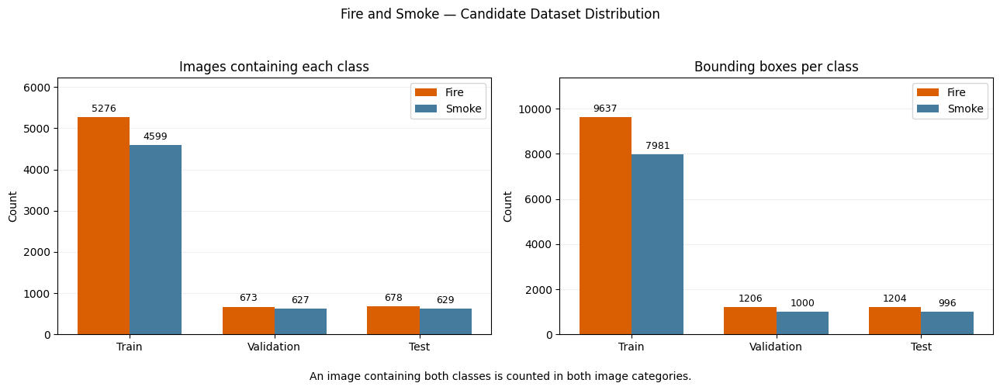

Figure saved: /content/candidate_analysis/candidate_class_distribution.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare the class counts for each split.
split_labels = ["Train", "Validation", "Test"]
positions = np.arange(len(SPLITS))
bar_width = 0.36

fire_images = [class_stats[s]["images"][0] for s in SPLITS]
smoke_images = [class_stats[s]["images"][1] for s in SPLITS]
fire_boxes = [class_stats[s]["boxes"][0] for s in SPLITS]
smoke_boxes = [class_stats[s]["boxes"][1] for s in SPLITS]

# Compare image-level and bounding-box-level distributions.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

panels = [
    (axes[0], fire_images, smoke_images, "Images containing each class"),
    (axes[1], fire_boxes, smoke_boxes, "Bounding boxes per class"),
]

for axis, fire_counts, smoke_counts, title in panels:
    fire_bars = axis.bar(
        positions - bar_width / 2,
        fire_counts,
        bar_width,
        label="Fire",
        color="#D95F02",
    )
    smoke_bars = axis.bar(
        positions + bar_width / 2,
        smoke_counts,
        bar_width,
        label="Smoke",
        color="#457B9D",
    )

    # Display counts above the bars.
    axis.bar_label(fire_bars, fmt="%.0f", padding=3, fontsize=9)
    axis.bar_label(smoke_bars, fmt="%.0f", padding=3, fontsize=9)

    axis.set_xticks(positions, split_labels)
    axis.set_ylabel("Count")
    axis.set_title(title)
    axis.set_ylim(
        0, max(max(fire_counts), max(smoke_counts)) * 1.18
    )
    axis.legend()
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)

fig.suptitle("Fire and Smoke — Candidate Dataset Distribution")
fig.text(
    0.5,
    0.02,
    "An image containing both classes is counted in both image categories.",
    ha="center",
    fontsize=10,
)

fig.tight_layout(rect=[0, 0.06, 1, 0.94])

# Save a high-resolution figure for the methodology report.
figure_path = ANALYSIS_DIR / "candidate_class_distribution.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print(f"Figure saved: {figure_path}")

In [ ]:
import shutil
from google.colab import files

# Package the analysis reports and figure for permanent local storage.
analysis_zip = shutil.make_archive(
    "/content/candidate_analysis_reports",
    "zip",
    root_dir=ANALYSIS_DIR,
)

print(f"Download archive: {analysis_zip}")
files.download(analysis_zip)

Download archive: /content/candidate_analysis_reports.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from uuid import uuid4
import shutil

# Select the candidate dataset.
CANDIDATE_ZIP = Path("/content/fire_smoke_grouped_candidate.zip")
assert CANDIDATE_ZIP.is_file(), "Upload the candidate ZIP first."

# Create a separate working copy for annotation corrections.
WORK_ROOT = Path(f"/content/fire_smoke_cleaning_{uuid4().hex[:8]}")
WORK_ROOT.mkdir(parents=True)

with ZipFile(CANDIDATE_ZIP) as archive:
    # Extract only the dataset, excluding reports and quarantined files.
    members = [
        member for member in archive.infolist()
        if not member.is_dir()
        and PurePosixPath(member.filename).parts[0] == "dataset"
    ]
    assert members, "The archive does not contain a dataset folder."

    for member in members:
        relative_path = PurePosixPath(member.filename)

        # Reject unsafe archive paths.
        assert not relative_path.is_absolute()
        assert ".." not in relative_path.parts

        destination = WORK_ROOT.joinpath(*relative_path.parts)
        destination.parent.mkdir(parents=True, exist_ok=True)

        with archive.open(member) as source:
            with destination.open("wb") as target:
                shutil.copyfileobj(source, target)

DATASET_ROOT = WORK_ROOT / "dataset"

# Verify the extracted image and label counts.
expected_counts = {"train": 7876, "valid": 986, "test": 986}
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split, expected in expected_counts.items():
    images = [
        path for path in (DATASET_ROOT / split / "images").iterdir()
        if path.suffix.lower() in image_extensions
    ]
    labels = list((DATASET_ROOT / split / "labels").glob("*.txt"))

    assert len(images) == len(labels) == expected, (
        f"Unexpected file counts in {split}."
    )
    print(f"{split}: {len(images):,} images, {len(labels):,} labels")

print(f"\nWorking dataset: {DATASET_ROOT}")
print("Working copy created. Annotation corrections have not started.")

train: 7,876 images, 7,876 labels
valid: 986 images, 986 labels
test: 986 images, 986 labels

Working dataset: /content/fire_smoke_cleaning_4f3c6adb/dataset
Working copy created. Annotation corrections have not started.


In [ ]:
import csv
import io
import json
from collections import Counter
from pathlib import Path
from zipfile import ZipFile

ORIGINAL_ZIP = Path("/content/MyData_Fire.zip")
assert ORIGINAL_ZIP.is_file(), "Upload MyData_Fire.zip first."
assert DATASET_ROOT.is_dir(), "Run the working-copy cell first."

# Read the mapping between original images and candidate images.
with ZipFile(CANDIDATE_ZIP) as candidate:
    manifest_files = [
        name for name in candidate.namelist()
        if Path(name).name == "candidate_manifest.csv"
    ]
    assert len(manifest_files) == 1, "Candidate manifest not found."

    manifest_text = candidate.read(
        manifest_files[0]
    ).decode("utf-8-sig")

    manifest = list(csv.DictReader(io.StringIO(manifest_text)))

review_queue = []

with ZipFile(ORIGINAL_ZIP) as original:
    original_names = set(original.namelist())

    # Group original copies by the image hash recorded in the manifest.
    import hashlib

    copies_by_hash = {}
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    for name in original.namelist():
        parts = Path(name).parts

        if (
            len(parts) != 3
            or parts[0] not in ("train", "valid", "test")
            or parts[1] != "images"
            or Path(name).suffix.lower() not in image_extensions
        ):
            continue

        digest = hashlib.sha256(original.read(name)).hexdigest()
        copies_by_hash.setdefault(digest, []).append(name)

    for row in manifest:
        copies = copies_by_hash.get(row["image_sha256"], [])

        if len(copies) < 2:
            continue

        variants = []

        for image_path in copies:
            split = image_path.split("/")[0]
            label_path = f"{split}/labels/{Path(image_path).stem}.txt"
            assert label_path in original_names, label_path

            text = original.read(label_path).decode("utf-8-sig")

            # Ignore row order and repeated identical boxes.
            boxes = sorted({
                tuple(map(float, line.split()))
                for line in text.splitlines()
                if line.strip()
            })

            variants.append({
                "original_image": image_path,
                "boxes": boxes,
            })

        if all(v["boxes"] == variants[0]["boxes"] for v in variants):
            continue

        class_sets = [
            {int(box[0]) for box in v["boxes"]}
            for v in variants
        ]

        if any(classes != class_sets[0] for classes in class_sets):
            reason = "class_presence"
        elif any(
            len(v["boxes"]) != len(variants[0]["boxes"])
            for v in variants
        ):
            reason = "box_count"
        else:
            reason = "box_coordinates"

        working_image = DATASET_ROOT.parent / row["candidate_image"]
        assert working_image.is_file(), str(working_image)

        review_queue.append({
            "candidate_image": row["candidate_image"],
            "retained_original": row["original_image"],
            "reason": reason,
            "status": "pending",
            "variants": variants,
        })

# Review class-presence disagreements first.
priority = {"class_presence": 0, "box_count": 1, "box_coordinates": 2}
review_queue.sort(
    key=lambda item: (
        priority[item["reason"]],
        item["candidate_image"],
    )
)

for index, item in enumerate(review_queue, start=1):
    item["review_id"] = f"AR{index:04d}"

REVIEW_DIR = DATASET_ROOT.parent / "annotation_review"
REVIEW_DIR.mkdir(exist_ok=True)

queue_path = REVIEW_DIR / "review_queue.json"
queue_path.write_text(
    json.dumps(review_queue, indent=2),
    encoding="utf-8",
)

print("ANNOTATION REVIEW QUEUE")
for reason, count in Counter(
    item["reason"] for item in review_queue
).items():
    print(f"{reason}: {count:,} groups")

print(f"\nTotal: {len(review_queue):,} groups")
print(f"Queue saved: {queue_path}")
print("No images or annotations were modified.")

ANNOTATION REVIEW QUEUE
class_presence: 228 groups
box_count: 547 groups
box_coordinates: 381 groups

Total: 1,156 groups
Queue saved: /content/fire_smoke_cleaning_4f3c6adb/annotation_review/review_queue.json
No images or annotations were modified.


In [ ]:
from PIL import Image, ImageDraw
import math
import shutil

# Export class-presence disagreements as side-by-side JPG comparisons.
PRIORITY_DIR = REVIEW_DIR / "class_presence_comparisons"
PRIORITY_DIR.mkdir(exist_ok=True)

priority_cases = [
    item for item in review_queue
    if item["reason"] == "class_presence"
]

with ZipFile(ORIGINAL_ZIP) as original:
    for index, item in enumerate(priority_cases, start=1):
        variants = item["variants"]
        columns = 2
        rows = math.ceil(len(variants) / columns)

        cell_width = 600
        cell_height = 580

        sheet = Image.new(
            "RGB",
            (columns * cell_width, 60 + rows * cell_height),
            "white",
        )
        draw = ImageDraw.Draw(sheet)

        draw.text(
            (15, 15),
            f"{item['review_id']} | Class disagreement | Pending review",
            fill="black",
        )

        for version, variant in enumerate(variants):
            column = version % columns
            row = version // columns
            left = column * cell_width + 10
            top = 60 + row * cell_height

            # Identify the annotations currently used in the working copy.
            is_current = (
                variant["original_image"] == item["retained_original"]
            )
            status = "CURRENT COPY" if is_current else "ALTERNATIVE COPY"

            draw.text(
                (left, top),
                f"Version {version + 1} | {status}",
                fill="black",
            )
            draw.text(
                (left, top + 20),
                f"Boxes: {len(variant['boxes'])}",
                fill="black",
            )

            with Image.open(
                io.BytesIO(original.read(variant["original_image"]))
            ) as source:
                image = source.convert("RGB")

            image.thumbnail((580, 510))
            image_top = top + 45
            sheet.paste(image, (left, image_top))

            # Draw each version's original annotations.
            for class_id, cx, cy, width, height in variant["boxes"]:
                x1 = left + (cx - width / 2) * image.width
                y1 = image_top + (cy - height / 2) * image.height
                x2 = left + (cx + width / 2) * image.width
                y2 = image_top + (cy + height / 2) * image.height

                color = "red" if int(class_id) == 0 else "cyan"
                label = "fire" if int(class_id) == 0 else "smoke"

                draw.rectangle((x1, y1, x2, y2), outline=color, width=2)
                draw.text(
                    (x1, y1),
                    label,
                    fill=color,
                    stroke_width=1,
                    stroke_fill="black",
                )

        sheet.save(
            PRIORITY_DIR / f"{item['review_id']}.jpg",
            quality=95,
        )

        if index % 50 == 0 or index == len(priority_cases):
            print(f"Exported: {index}/{len(priority_cases)}")

# Include the review records to preserve image identities.
(PRIORITY_DIR / "review_records.json").write_text(
    json.dumps(priority_cases, indent=2),
    encoding="utf-8",
)

priority_zip = shutil.make_archive(
    str(REVIEW_DIR / "class_presence_review"),
    "zip",
    root_dir=PRIORITY_DIR,
)

print(f"\nReview archive: {priority_zip}")
print("CURRENT COPY indicates the selected copy, not verified quality.")
print("No dataset annotations were changed.")

Exported: 50/228
Exported: 100/228
Exported: 150/228
Exported: 200/228
Exported: 228/228

Review archive: /content/fire_smoke_cleaning_4f3c6adb/annotation_review/class_presence_review.zip
CURRENT COPY indicates the selected copy, not verified quality.
No dataset annotations were changed.


In [ ]:
from google.colab import files

# Download the comparison images and their review records.
files.download(priority_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import subprocess
import sys

# Locate the correction package.
PATCH_ZIP = Path("/content/annotation_corrections_batch01.zip")
assert PATCH_ZIP.is_file(), "Upload the correction package first."
assert DATASET_ROOT.is_dir(), "The working dataset is unavailable."

# Extract only the correction records and application script.
PATCH_DIR = DATASET_ROOT.parent / "corrections_batch01"
PATCH_DIR.mkdir(exist_ok=True)

with ZipFile(PATCH_ZIP) as archive:
    for name in ("annotation_patch.json", "apply_batch.py"):
        (PATCH_DIR / name).write_bytes(archive.read(name))

# Verify image identities and existing labels before applying corrections.
# Original labels are backed up beside the working dataset.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Correction batch stopped. Check the error above.")

{
  "batch": "01",
  "changed_labels_this_run": 6,
  "already_applied": 0,
  "total_targeted_corrections": 6,
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch01",
  "dataset_status": "Annotation review in progress; not final."
}



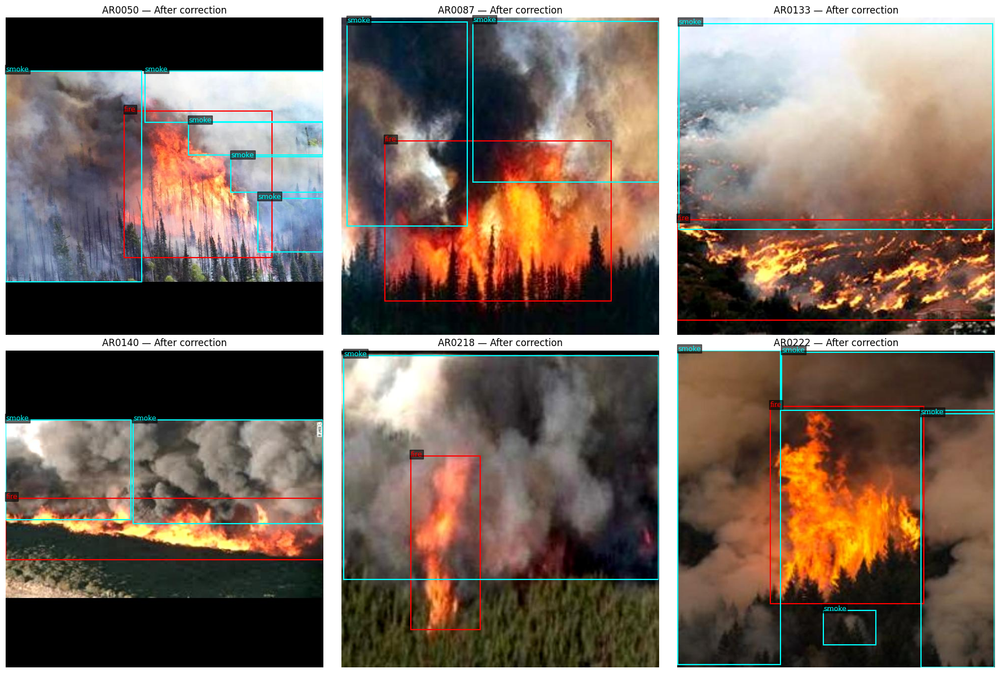

In [ ]:
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# Read the applied correction records.
patch = json.loads(
    (PATCH_DIR / "annotation_patch.json").read_text(encoding="utf-8")
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for axis, change in zip(axes.flat, patch["changes"]):
    # Load the image and its current annotations from the working copy.
    image_path = DATASET_ROOT.parent / change["candidate_image"]
    label_path = DATASET_ROOT.parent / change["label_path"]

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    axis.imshow(image)

    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue

        class_id, cx, cy, width, height = map(float, line.split())
        color = "red" if int(class_id) == 0 else "cyan"
        name = "fire" if int(class_id) == 0 else "smoke"

        x = (cx - width / 2) * image.width
        y = (cy - height / 2) * image.height

        axis.add_patch(
            Rectangle(
                (x, y),
                width * image.width,
                height * image.height,
                fill=False,
                edgecolor=color,
                linewidth=1.5,
            )
        )
        axis.text(
            x, y, name,
            color=color,
            fontsize=9,
            bbox={"facecolor": "black", "alpha": 0.6, "pad": 1},
        )

    axis.set_title(f"{change['review_id']} — After correction")
    axis.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import subprocess
import sys

# Locate the second correction package.
PATCH2_ZIP = Path("/content/annotation_corrections_batch02.zip")
assert PATCH2_ZIP.is_file(), "Upload annotation_corrections_batch02.zip first."
assert DATASET_ROOT.is_dir(), "The working dataset is unavailable."

# Extract the application script and correction records.
PATCH2_DIR = DATASET_ROOT.parent / "corrections_batch02"
PATCH2_DIR.mkdir(exist_ok=True)

with ZipFile(PATCH2_ZIP) as archive:
    for name in ("annotation_patch.json", "apply_batch.py"):
        (PATCH2_DIR / name).write_bytes(archive.read(name))

# Verify batch 01, back up existing labels, and apply batch 02.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH2_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Batch 02 stopped. Check the error above.")

{
  "batch": "02",
  "changed_labels_this_run": 82,
  "already_applied": 0,
  "total_batch02_corrections": 82,
  "previous_corrections_preserved": 6,
  "total_images": 9848,
  "splits": {
    "train": {
      "images": 7876,
      "fire_boxes": 9849,
      "smoke_boxes": 7984
    },
    "valid": {
      "images": 986,
      "fire_boxes": 1217,
      "smoke_boxes": 999
    },
    "test": {
      "images": 986,
      "fire_boxes": 1220,
      "smoke_boxes": 996
    }
  },
  "held_class_omission_cases": 20,
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch02",
  "dataset_status": "Annotation review in progress; not final."
}



In [ ]:
import shutil
from google.colab import files

# Save the working dataset, correction records, and label backups.
checkpoint_zip = shutil.make_archive(
    "/content/fire_smoke_working_checkpoint_batch02",
    "zip",
    root_dir=DATASET_ROOT.parent,
)

print(f"Checkpoint saved: {checkpoint_zip}")
print("Annotation review is still in progress.")
files.download(checkpoint_zip)

Checkpoint saved: /content/fire_smoke_working_checkpoint_batch02.zip
Annotation review is still in progress.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import subprocess
import sys

# Locate the third correction package.
PATCH3_ZIP = Path("/content/annotation_corrections_batch03.zip")
assert PATCH3_ZIP.is_file(), "Upload annotation_corrections_batch03.zip first."
assert DATASET_ROOT.is_dir(), "The working dataset is unavailable."

# Extract the correction script and records.
PATCH3_DIR = DATASET_ROOT.parent / "corrections_batch03"
PATCH3_DIR.mkdir(exist_ok=True)

with ZipFile(PATCH3_ZIP) as archive:
    for name in ("annotation_patch.json", "apply_batch.py"):
        (PATCH3_DIR / name).write_bytes(archive.read(name))

# Preserve earlier corrections and back up labels before applying changes.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH3_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Batch 03 stopped. Check the error above.")

{
  "batch": "03",
  "changed_labels_this_run": 15,
  "already_applied": 0,
  "total_batch03_corrections": 15,
  "previous_corrections_preserved": 88,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "unchanged_uncertain_cases": 5,
  "corrected_cases_with_additional_uncertain_regions": 7,
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch03",
  "dataset_status": "Targeted corrections applied; annotation review remains incomplete."
}



In [ ]:
from pathlib import Path
from zipfile import ZipFile
import subprocess
import sys

# Select the expanded fourth correction package.
PATCH4_ZIP = Path("/content/annotation_corrections_batch04_expanded.zip")
assert PATCH4_ZIP.is_file(), "Upload the expanded correction package first."
assert DATASET_ROOT.is_dir(), "The working dataset is unavailable."

# Extract the correction script and records.
PATCH4_DIR = DATASET_ROOT.parent / "corrections_batch04_expanded"
PATCH4_DIR.mkdir(exist_ok=True)

with ZipFile(PATCH4_ZIP) as archive:
    for name in ("annotation_patch.json", "apply_batch.py"):
        (PATCH4_DIR / name).write_bytes(archive.read(name))

# Verify earlier corrections, save backups, and apply the expanded batch.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH4_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Expanded batch 04 stopped. Check the error above.")

{
  "batch": "04",
  "variant": "expanded",
  "changed_labels_this_run": 56,
  "already_applied": 0,
  "total_batch04_corrections": 56,
  "previous_corrections_preserved": 103,
  "total_targeted_label_corrections_across_batches": 159,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch04_expanded",
  "dataset_status": "Targeted corrections applied; annotation review remains incomplete."
}



In [ ]:
import shutil
from google.colab import files

# Save the updated dataset, correction records, and label backups.
checkpoint_zip = shutil.make_archive(
    "/content/fire_smoke_working_checkpoint_batch04",
    "zip",
    root_dir=DATASET_ROOT.parent,
)

print(f"Updated checkpoint: {checkpoint_zip}")
print("Annotation review is still in progress.")
files.download(checkpoint_zip)

Updated checkpoint: /content/fire_smoke_working_checkpoint_batch04.zip
Annotation review is still in progress.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from uuid import uuid4
import subprocess
import sys
import zipfile

# Locate the correction package and the current working dataset.
PATCH_ZIP = Path("/content/annotation_corrections_batch05.zip")

assert PATCH_ZIP.is_file(), "Upload annotation_corrections_batch05.zip first."
assert "DATASET_ROOT" in globals(), "Restore the working dataset first."
assert Path(DATASET_ROOT).is_dir(), "The working dataset is unavailable."

# Extract the package into a unique folder.
PATCH_DIR = Path(f"/content/batch05_{uuid4().hex[:8]}")
PATCH_DIR.mkdir()

with zipfile.ZipFile(PATCH_ZIP) as archive:
    archive.extractall(PATCH_DIR)

# Validate previous corrections, back up labels, and apply batch 05.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Batch 05 stopped. Check the error above.")

{
  "batch": "05",
  "screened_cases": 300,
  "changed_labels_this_run": 17,
  "already_applied": 0,
  "total_batch05_corrections": 17,
  "previous_corrections_preserved": 159,
  "total_targeted_label_corrections_across_batches": 176,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch05",
  "dataset_status": "Targeted fire corrections applied. Full annotation review remains incomplete."
}



In [ ]:
from pathlib import Path
from uuid import uuid4
import subprocess
import sys
import zipfile

# Locate the package and the current working dataset.
PATCH_ZIP = Path("/content/annotation_corrections_batch06.zip")

assert PATCH_ZIP.is_file(), "Upload annotation_corrections_batch06.zip first."
assert "DATASET_ROOT" in globals(), "Restore the working dataset first."
assert Path(DATASET_ROOT).is_dir(), "The working dataset is unavailable."

# Extract the correction package into a unique folder.
PATCH_DIR = Path(f"/content/batch06_{uuid4().hex[:8]}")
PATCH_DIR.mkdir()

with zipfile.ZipFile(PATCH_ZIP) as archive:
    archive.extractall(PATCH_DIR)

# Validate previous corrections, save backups, and apply batch 06.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Batch 06 stopped. Check the error above.")


{
  "batch": "06",
  "screened_cases": 300,
  "changed_labels_this_run": 42,
  "already_applied": 0,
  "total_batch06_corrections": 42,
  "previous_corrections_preserved": 176,
  "total_targeted_label_corrections_across_batches": 218,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch06",
  "dataset_status": "Targeted fire corrections applied. Full annotation review remains incomplete."
}



In [ ]:
from pathlib import Path
from uuid import uuid4
import subprocess
import sys
import zipfile

# Locate the package and the current working dataset.
PATCH_ZIP = Path("/content/annotation_corrections_batch07.zip")

assert PATCH_ZIP.is_file(), "Upload annotation_corrections_batch07.zip first."
assert "DATASET_ROOT" in globals(), "Restore the working dataset first."
assert Path(DATASET_ROOT).is_dir(), "The working dataset is unavailable."

# Extract the package into a unique folder.
PATCH_DIR = Path(f"/content/batch07_{uuid4().hex[:8]}")
PATCH_DIR.mkdir()

with zipfile.ZipFile(PATCH_ZIP) as archive:
    archive.extractall(PATCH_DIR)

# Validate earlier corrections, save backups, and apply batch 07.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Batch 07 stopped. Check the error above.")

{
  "batch": "07",
  "screened_cases": 300,
  "changed_labels_this_run": 18,
  "already_applied": 0,
  "total_batch07_corrections": 18,
  "previous_corrections_preserved": 218,
  "total_targeted_label_corrections_across_batches": 236,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch07",
  "dataset_status": "Targeted fire corrections applied. Full annotation review remains incomplete."
}



In [ ]:
from pathlib import Path
from uuid import uuid4
import subprocess
import sys
import zipfile

# Locate the package and the current working dataset.
PATCH_ZIP = Path("/content/annotation_corrections_batch08.zip")

assert PATCH_ZIP.is_file(), "Upload annotation_corrections_batch08.zip first."
assert "DATASET_ROOT" in globals(), "Restore the working dataset first."
assert Path(DATASET_ROOT).is_dir(), "The working dataset is unavailable."

# Extract the package into a unique folder.
PATCH_DIR = Path(f"/content/batch08_{uuid4().hex[:8]}")
PATCH_DIR.mkdir()

with zipfile.ZipFile(PATCH_ZIP) as archive:
    archive.extractall(PATCH_DIR)

# Validate previous corrections, save backups, and apply batch 08.
result = subprocess.run(
    [
        sys.executable,
        str(PATCH_DIR / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Batch 08 stopped. Check the error above.")

{
  "batch": "08",
  "screened_cases": 97,
  "changed_labels_this_run": 3,
  "already_applied": 0,
  "total_batch08_corrections": 3,
  "previous_corrections_preserved": 236,
  "total_targeted_label_corrections_across_batches": 239,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch08",
  "dataset_status": "Targeted fire corrections applied. Full annotation review remains incomplete."
}



In [ ]:
from pathlib import Path
from zipfile import ZipFile
import subprocess
import sys

# Locate the uploaded correction package.
patch_zip = Path("/content/annotation_corrections_batch09.zip")
assert patch_zip.is_file(), "Upload annotation_corrections_batch09.zip first."
assert DATASET_ROOT.is_dir(), "The working dataset is unavailable."

# Extract the correction package.
patch_dir = Path("/content/annotation_corrections_batch09")
with ZipFile(patch_zip) as archive:
    archive.extractall(patch_dir)

# Verify previous corrections, back up the label, and apply the correction.
subprocess.run(
    [
        sys.executable,
        str(patch_dir / "apply_batch.py"),
        "--dataset",
        str(DATASET_ROOT),
    ],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '/content/annotation_corrections_batch09/apply_batch.py', '--dataset', '/content/fire_smoke_cleaning_4f3c6adb/dataset'], returncode=0)

In [ ]:
import json
from pathlib import Path

# Read the saved batch 09 application report.
report_path = Path(DATASET_ROOT).parent / "annotation_batch09_result.json"
assert report_path.is_file(), "Batch 09 report was not found."

report = json.loads(report_path.read_text(encoding="utf-8"))
print(json.dumps(report, indent=2))

{
  "batch": "09",
  "screened_cases": 12,
  "changed_labels_this_run": 1,
  "already_applied": 0,
  "total_batch09_corrections": 1,
  "previous_corrections_preserved": 239,
  "total_targeted_label_corrections_across_batches": 240,
  "total_images": 9848,
  "split_images": {
    "train": 7876,
    "valid": 986,
    "test": 986
  },
  "backup_directory": "/content/fire_smoke_cleaning_4f3c6adb/annotation_backups_batch09",
  "dataset_status": "Targeted fire corrections applied. Full annotation review remains incomplete."
}


In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image
import hashlib
import json
import math

# Use the current working dataset.
root = Path(DATASET_ROOT)
assert root.is_dir(), "The working dataset is unavailable."

report_dir = root.parent / "final_audit_batch09"
report_dir.mkdir(exist_ok=True)

expected_counts = {"train": 7876, "valid": 986, "test": 986}
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

issues = []
stats = {}
pixel_hashes = defaultdict(list)

for split, expected in expected_counts.items():
    image_dir = root / split / "images"
    label_dir = root / split / "labels"

    images = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )
    labels = set(label_dir.glob("*.txt"))
    expected_labels = {label_dir / f"{p.stem}.txt" for p in images}

    split_stats = Counter(images=len(images), labels=len(labels))

    # Check image-label pairing and split counts.
    if len({p.stem for p in images}) != len(images):
        issues.append(f"{split}: repeated image stems")

    for path in sorted(expected_labels - labels):
        issues.append(f"Missing label: {path.relative_to(root)}")

    for path in sorted(labels - expected_labels):
        issues.append(f"Orphan label: {path.relative_to(root)}")

    if len(images) != expected or len(labels) != expected:
        issues.append(f"{split}: unexpected image or label count")

    for index, image_path in enumerate(images, start=1):
        relative_image = image_path.relative_to(root).as_posix()

        # Fully decode each image and hash its RGB pixels.
        try:
            with Image.open(image_path) as source:
                source.load()
                rgb = source.convert("RGB")
                digest = hashlib.sha256()
                digest.update(f"{rgb.width},{rgb.height}:".encode())
                digest.update(rgb.tobytes())

            pixel_hashes[digest.hexdigest()].append(relative_image)
            split_stats["decoded_images"] += 1
        except Exception as error:
            issues.append(f"Invalid image: {relative_image}: {error}")

        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.is_file():
            continue

        # Validate YOLO rows and count classes.
        seen_rows = set()
        classes_present = set()

        try:
            lines = label_path.read_text(encoding="utf-8").splitlines()
            nonempty_lines = [line for line in lines if line.strip()]

            if not nonempty_lines:
                split_stats["empty_labels"] += 1
                issues.append(f"Empty label requires review: {relative_image}")

            for line_number, line in enumerate(nonempty_lines, start=1):
                values = tuple(map(float, line.split()))
                assert len(values) == 5, "Expected five values"
                assert all(math.isfinite(v) for v in values), "Non-finite value"

                cls, x, y, width, height = values
                assert cls in (0, 1), "Invalid class"
                assert width > 0 and height > 0, "Non-positive box size"
                assert min(x - width / 2, y - height / 2) >= -1e-7, \
                    "Box extends outside image"
                assert max(x + width / 2, y + height / 2) <= 1 + 1e-7, \
                    "Box extends outside image"
                assert values not in seen_rows, "Repeated annotation row"

                seen_rows.add(values)
                classes_present.add(int(cls))
                class_name = "fire" if cls == 0 else "smoke"
                split_stats[f"{class_name}_boxes"] += 1

            for cls in classes_present:
                class_name = "fire" if cls == 0 else "smoke"
                split_stats[f"{class_name}_images"] += 1

            if classes_present == {0, 1}:
                split_stats["both_classes_images"] += 1

        except Exception as error:
            issues.append(f"Invalid label: {relative_image}: {error}")

        if index % 1000 == 0:
            print(f"{split}: {index:,}/{len(images):,} checked")

    stats[split] = dict(split_stats)
    print(f"Completed: {split}")

# Check exact pixel duplicates within and across all splits.
duplicate_groups = [
    paths for paths in pixel_hashes.values() if len(paths) > 1
]
if duplicate_groups:
    issues.append(f"Exact duplicate image groups: {len(duplicate_groups)}")

# Verify every correction recorded through batch 09.
patch_path = Path(
    "/content/annotation_corrections_batch09/annotation_patch.json"
)
verified_corrections = 0

if patch_path.is_file():
    patch = json.loads(patch_path.read_text(encoding="utf-8"))
    corrections = patch["prerequisite_changes"] + patch["changes"]

    if len({c["label_path"] for c in corrections}) != 240:
        issues.append("The correction manifest does not contain 240 unique labels")

    for change in corrections:
        label_path = root / Path(change["label_path"]).relative_to("dataset")
        image_path = root / Path(change["candidate_image"]).relative_to("dataset")

        label_matches = (
            label_path.is_file()
            and label_path.read_bytes() == change["after_text"].encode("utf-8")
        )
        image_matches = (
            image_path.is_file()
            and hashlib.sha256(image_path.read_bytes()).hexdigest()
            == change["image_sha256"]
        )

        if label_matches and image_matches:
            verified_corrections += 1
        else:
            issues.append(f"Correction mismatch: {change['candidate_image']}")
else:
    issues.append("Batch 09 correction manifest is unavailable")

# Save the audit results and updated class statistics.
summary = {
    "dataset": str(root),
    "splits": stats,
    "total_images": sum(s["images"] for s in stats.values()),
    "verified_corrected_labels": verified_corrections,
    "exact_duplicate_groups": len(duplicate_groups),
    "issue_count": len(issues),
    "technical_checks_passed": not issues and verified_corrections == 240,
    "full_annotation_review_complete": False,
    "limitations": [
        "Pixel hashing detects exact duplicates, not all related scenes.",
        "Valid coordinates do not prove semantic annotation correctness.",
        "This check does not certify every object is annotated.",
    ],
}

for name, content in [
    ("summary.json", summary),
    ("issues.json", issues),
    ("exact_duplicate_groups.json", duplicate_groups),
]:
    (report_dir / name).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

print(json.dumps(summary, indent=2))
print(f"\nReports saved to: {report_dir}")

if issues:
    print("\nFirst issues:")
    for issue in issues[:20]:
        print("-", issue)

train: 1,000/7,876 checked
train: 2,000/7,876 checked
train: 3,000/7,876 checked
train: 4,000/7,876 checked
train: 5,000/7,876 checked
train: 6,000/7,876 checked
train: 7,000/7,876 checked
Completed: train
Completed: valid
Completed: test
{
  "dataset": "/content/fire_smoke_cleaning_4f3c6adb/dataset",
  "splits": {
    "train": {
      "images": 7876,
      "labels": 7876,
      "decoded_images": 7876,
      "fire_boxes": 10079,
      "fire_images": 5467,
      "smoke_boxes": 7983,
      "smoke_images": 4600,
      "both_classes_images": 2191
    },
    "valid": {
      "images": 986,
      "labels": 986,
      "decoded_images": 986,
      "smoke_boxes": 999,
      "smoke_images": 628,
      "fire_boxes": 1237,
      "fire_images": 688,
      "both_classes_images": 330
    },
    "test": {
      "images": 986,
      "labels": 986,
      "decoded_images": 986,
      "fire_boxes": 1250,
      "smoke_boxes": 996,
      "fire_images": 699,
      "smoke_images": 629,
      "both_classes_ima

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import json

# Confirm that the saved audit passed.
root = Path(DATASET_ROOT)
audit_dir = root.parent / "final_audit_batch09"
summary = json.loads(
    (audit_dir / "summary.json").read_text(encoding="utf-8")
)

assert summary["technical_checks_passed"], "The audit must pass first."
assert summary["verified_corrected_labels"] == 240

# Create an archive containing the current dataset and its records.
output_zip = Path("/content/fire_smoke_cleaned_batch09.zip")
patch_path = Path(
    "/content/annotation_corrections_batch09/annotation_patch.json"
)
assert patch_path.is_file(), "The correction manifest is unavailable."

with ZipFile(output_zip, "w", ZIP_DEFLATED) as archive:
    for path in sorted(root.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                (Path("dataset") / path.relative_to(root)).as_posix(),
            )

    for path in sorted(audit_dir.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                (Path("reports") / path.relative_to(audit_dir)).as_posix(),
            )

    archive.write(patch_path, "reports/corrections_through_batch09.json")
    archive.writestr(
        "README.txt",
        "Working dataset after batch 09.\n"
        "Images: 9848. Verified corrected label files: 240.\n"
        "Technical audit passed before export.\n"
        "Full semantic annotation review remains incomplete.\n"
        "Exact duplicate checks do not certify scene independence.\n",
    )

# Verify archive integrity before downloading.
with ZipFile(output_zip) as archive:
    assert archive.testzip() is None, "Archive integrity check failed."

print(f"Saved: {output_zip}")
print(f"Size: {output_zip.stat().st_size / (1024 ** 2):.1f} MB")
files.download(str(output_zip))

Saved: /content/fire_smoke_cleaned_batch09.zip
Size: 460.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from collections import Counter
from pathlib import Path
from zipfile import ZipFile
import json

DATASET_ZIP = Path("/content/fire_smoke_consolidated_v2.zip")

if not DATASET_ZIP.is_file():
    raise FileNotFoundError(f"Upload {DATASET_ZIP.name} to /content first.")

with ZipFile(DATASET_ZIP) as archive:
    current_pairs = json.loads(
        archive.read("reports/remaining_weak_cross_split_candidates.json")
    )
    previous_review = json.loads(
        archive.read("reports/visual_weak_pair_review.json")
    )
    manifest = json.loads(archive.read("reports/split_manifest.json"))

# Match pairs by filename, regardless of order or split changes.
def pair_key(pair):
    return tuple(sorted((pair["a"], pair["b"])))

previous_by_pair = {
    pair_key(pair): pair["visual_decision"]
    for pair in previous_review
}

# Use the current image paths because some images moved between splits.
image_paths = {
    Path(row["output_image"]).name: row["output_image"]
    for row in manifest
    if row["output_image"].startswith("dataset/")
}

pending_pairs = []
status_counts = Counter()

for pair in current_pairs:
    decision = previous_by_pair.get(pair_key(pair), "new")
    status_counts[decision] += 1

    # A confirmed same-scene pair should be in one split.
    if decision != "no_visual_match":
        pending_pairs.append({
            **pair,
            "review_id": f"W{len(pending_pairs) + 1:03d}",
            "review_status": decision,
        })

print(f"Current cross-split candidates: {len(current_pairs)}")
print(f"Previously reviewed with no visual match: {status_counts['no_visual_match']}")
print(f"New candidates: {status_counts['new']}")
print(f"Previously inconclusive: {status_counts['inconclusive']}")
print(f"Confirmed same-scene pairs still crossing splits: {status_counts['same_scene']}")
print(f"Pairs to inspect: {len(pending_pairs)}")

Current cross-split candidates: 63
Previously reviewed with no visual match: 59
New candidates: 3
Previously inconclusive: 1
Confirmed same-scene pairs still crossing splits: 0
Pairs to inspect: 4


In [ ]:
from collections import Counter
from pathlib import Path
from zipfile import ZipFile
import json

DATASET_ZIP = Path("/content/fire_smoke_consolidated_v2.zip")

if not DATASET_ZIP.is_file():
    raise FileNotFoundError(f"Upload {DATASET_ZIP.name} to /content first.")

with ZipFile(DATASET_ZIP) as archive:
    current_pairs = json.loads(
        archive.read("reports/remaining_weak_cross_split_candidates.json")
    )
    previous_review = json.loads(
        archive.read("reports/visual_weak_pair_review.json")
    )
    manifest = json.loads(archive.read("reports/split_manifest.json"))

# Match pairs by filename, regardless of order or split changes.
def pair_key(pair):
    return tuple(sorted((pair["a"], pair["b"])))

previous_by_pair = {
    pair_key(pair): pair["visual_decision"]
    for pair in previous_review
}

# Use the current image paths because some images moved between splits.
image_paths = {
    Path(row["output_image"]).name: row["output_image"]
    for row in manifest
    if row["output_image"].startswith("dataset/")
}

pending_pairs = []
status_counts = Counter()

for pair in current_pairs:
    decision = previous_by_pair.get(pair_key(pair), "new")
    status_counts[decision] += 1

    # A confirmed same-scene pair should be in one split.
    if decision != "no_visual_match":
        pending_pairs.append({
            **pair,
            "review_id": f"W{len(pending_pairs) + 1:03d}",
            "review_status": decision,
        })

print(f"Current cross-split candidates: {len(current_pairs)}")
print(f"Previously reviewed with no visual match: {status_counts['no_visual_match']}")
print(f"New candidates: {status_counts['new']}")
print(f"Previously inconclusive: {status_counts['inconclusive']}")
print(f"Confirmed same-scene pairs still crossing splits: {status_counts['same_scene']}")
print(f"Pairs to inspect: {len(pending_pairs)}")

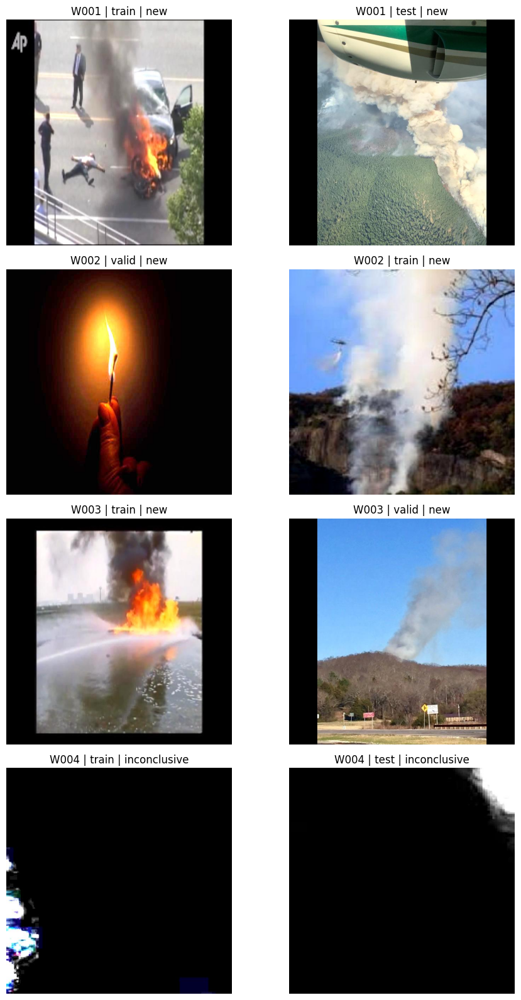

In [4]:
from io import BytesIO

import matplotlib.pyplot as plt
from PIL import Image

# Display up to six pending pairs at a time.
START_INDEX = 0
PAGE_SIZE = 6
page = pending_pairs[START_INDEX:START_INDEX + PAGE_SIZE]

if not page:
    print("No pending pairs on this page.")
else:
    fig, axes = plt.subplots(len(page), 2, figsize=(10, 4 * len(page)), squeeze=False)

    with ZipFile(DATASET_ZIP) as archive:
        for row, pair in zip(axes, page):
            for axis, side in zip(row, ("a", "b")):
                path = image_paths[pair[side]]
                split = path.split("/")[1]

                with Image.open(BytesIO(archive.read(path))) as image:
                    axis.imshow(image.convert("RGB"))

                axis.set_title(
                    f"{pair['review_id']} | {split} | {pair['review_status']}"
                )
                axis.axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
# Record visual decisions for the four displayed pairs.
decisions = {
    "W001": "no_visual_match",
    "W002": "no_visual_match",
    "W003": "no_visual_match",
    "W004": "inconclusive",
}

pairs_by_id = {pair["review_id"]: pair for pair in pending_pairs}
if set(pairs_by_id) != set(decisions):
    raise ValueError("The pending pairs differ from the four reviewed pairs.")

review_records = [
    {
        "review_id": review_id,
        "a": pairs_by_id[review_id]["a"],
        "b": pairs_by_id[review_id]["b"],
        "visual_decision": decision,
    }
    for review_id, decision in decisions.items()
]

review_path = Path("/content/v2_weak_pair_followup.json")
review_path.write_text(json.dumps(review_records, indent=2), encoding="utf-8")

print(f"Review saved to: {review_path}")
print("New pairs with no visual match: 3")
print("Inconclusive pairs: 1")

Review saved to: /content/v2_weak_pair_followup.json
New pairs with no visual match: 3
Inconclusive pairs: 1


Flagged smoke-only evaluation images: 116
Showing 1-12 of 116


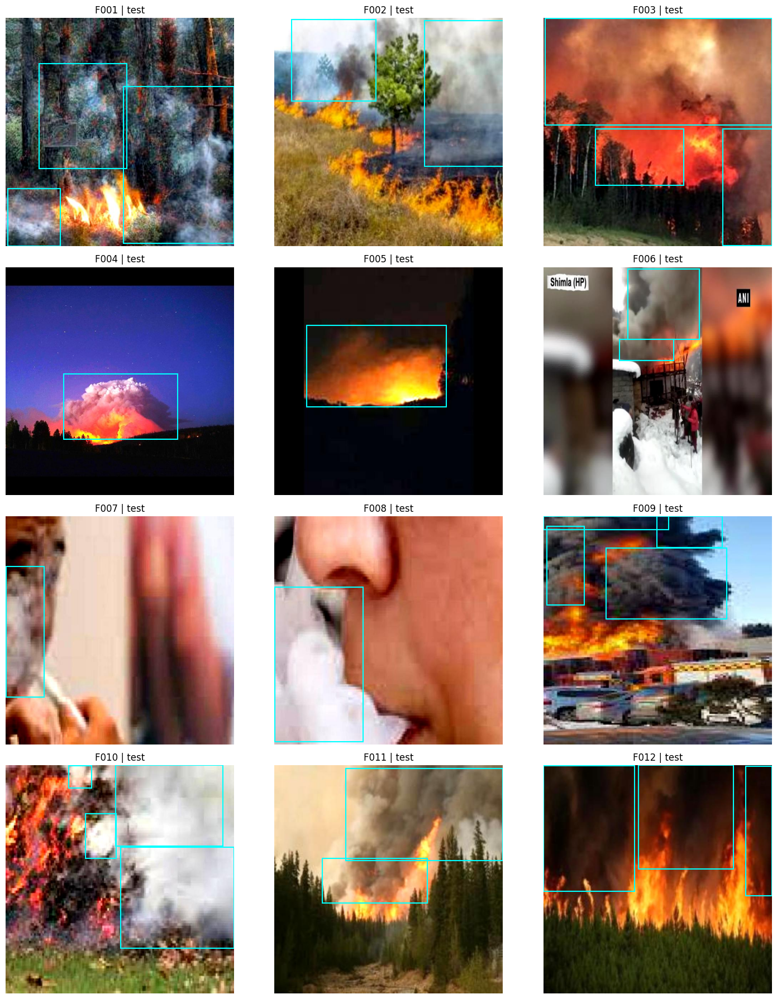

In [6]:
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

DATASET_ZIP = Path("/content/fire_smoke_consolidated_v2.zip")
if not DATASET_ZIP.is_file():
    raise FileNotFoundError(f"Upload {DATASET_ZIP.name} to /content first.")

PAGE_SIZE = 12
PAGE_INDEX = 0  # Set to 1 for the second page, 2 for the third, and so on.

with ZipFile(DATASET_ZIP) as archive:
    manifest = json.loads(archive.read("reports/split_manifest.json"))
    review_list = json.loads(archive.read("reports/label_review.json"))
    flagged_names = {record["name"] for record in review_list}

    # Use the current split and label files from the archive manifest.
    candidates = []
    for record in sorted(manifest, key=lambda row: row["output_image"]):
        image_path = record["output_image"]
        if not image_path.startswith(("dataset/valid/", "dataset/test/")):
            continue
        if Path(image_path).name not in flagged_names:
            continue

        label_path = record["output_label"]
        boxes = [
            tuple(map(float, line.split()))
            for line in archive.read(label_path).decode("utf-8").splitlines()
            if line.strip()
        ]
        if boxes and all(box[0] == 1 for box in boxes):
            candidates.append({
                "review_id": f"F{len(candidates) + 1:03d}",
                "image_path": image_path,
                "label_path": label_path,
                "boxes": boxes,
            })

    start = PAGE_INDEX * PAGE_SIZE
    page = candidates[start:start + PAGE_SIZE]

    print(f"Flagged smoke-only evaluation images: {len(candidates)}")
    if not page:
        print("No candidates on this page.")
    else:
        print(f"Showing {start + 1}-{start + len(page)} of {len(candidates)}")
        fig, axes = plt.subplots(4, 3, figsize=(15, 18))

        for axis in axes.flat:
            axis.axis("off")

        for axis, case in zip(axes.flat, page):
            path = case["image_path"]
            with Image.open(BytesIO(archive.read(path))) as source:
                image = source.convert("RGB")

            width, height = image.size
            axis.imshow(image)
            for _, x, y, w, h in case["boxes"]:
                axis.add_patch(Rectangle(
                    ((x - w / 2) * width, (y - h / 2) * height),
                    w * width,
                    h * height,
                    fill=False,
                    edgecolor="cyan",
                    linewidth=1.5,
                ))

            axis.set_title(f"{case['review_id']} | {path.split('/')[1]}")

        plt.tight_layout()
        plt.show()

In [7]:
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

from google.colab import files
from PIL import Image, ImageDraw

OUTPUT_ZIP = Path("/content/evaluation_label_review.zip")
COLUMNS = 5
IMAGES_PER_SHEET = 30
TILE_SIZE = 240
TITLE_HEIGHT = 24
ROW_HEIGHT = TILE_SIZE + TITLE_HEIGHT

# Export all review sheets in one run.
with ZipFile(DATASET_ZIP) as dataset, ZipFile(OUTPUT_ZIP, "w") as output:
    for start in range(0, len(candidates), IMAGES_PER_SHEET):
        batch = candidates[start:start + IMAGES_PER_SHEET]
        rows = (len(batch) + COLUMNS - 1) // COLUMNS
        sheet = Image.new("RGB", (COLUMNS * TILE_SIZE, rows * ROW_HEIGHT), "white")
        draw = ImageDraw.Draw(sheet)

        for index, case in enumerate(batch):
            x = (index % COLUMNS) * TILE_SIZE
            y = (index // COLUMNS) * ROW_HEIGHT
            path = case["image_path"]

            with Image.open(BytesIO(dataset.read(path))) as source:
                preview = source.convert("RGB")
            preview.thumbnail((TILE_SIZE, TILE_SIZE))
            width, height = preview.size
            overlay = ImageDraw.Draw(preview)

            # Draw existing smoke boxes on the preview only.
            for _, cx, cy, w, h in case["boxes"]:
                overlay.rectangle(
                    (
                        (cx - w / 2) * width,
                        (cy - h / 2) * height,
                        (cx + w / 2) * width,
                        (cy + h / 2) * height,
                    ),
                    outline="cyan",
                    width=2,
                )

            draw.text((x + 5, y + 5), f"{case['review_id']} | {path.split('/')[1]}", fill="black")
            sheet.paste(preview, (x + (TILE_SIZE - width) // 2, y + TITLE_HEIGHT))

        buffer = BytesIO()
        sheet.save(buffer, format="JPEG", quality=94)
        output.writestr(f"review_{start + 1:03d}_{start + len(batch):03d}.jpg", buffer.getvalue())

print(f"Exported {len(candidates)} review images to {OUTPUT_ZIP.name}.")
files.download(str(OUTPUT_ZIP))

Exported 116 review images to evaluation_label_review.zip.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from collections import Counter
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
import hashlib
import json

DATASET_ZIP = Path("/content/fire_smoke_cleaned_final_v2.zip")
EXPECTED_SHA256 = "79eebbe55eed9cab968a60d88dcc1310708e6309a3566cbaad67edfd00dbce88"
EXPECTED_COUNTS = {"train": 7723, "valid": 964, "test": 968}

if not DATASET_ZIP.is_file():
    raise FileNotFoundError(f"Upload {DATASET_ZIP.name} to /content first.")

# Verify that the uploaded archive matches the independently audited file.
with DATASET_ZIP.open("rb") as file:
    actual_sha256 = hashlib.file_digest(file, "sha256").hexdigest()

if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("The archive does not match the audited dataset version.")

# Verify image-label pairing and count the active dataset files.
image_counts = Counter()
with ZipFile(DATASET_ZIP) as archive:
    for split in EXPECTED_COUNTS:
        images = {
            PurePosixPath(name).stem
            for name in archive.namelist()
            if name.startswith(f"dataset/{split}/images/") and not name.endswith("/")
        }
        labels = {
            PurePosixPath(name).stem
            for name in archive.namelist()
            if name.startswith(f"dataset/{split}/labels/") and name.endswith(".txt")
        }
        if images != labels:
            raise ValueError(f"Image-label pairing failed for {split}.")
        image_counts[split] = len(images)

    if "dataset/data.yaml" not in archive.namelist():
        raise FileNotFoundError("dataset/data.yaml is missing from the archive.")

if dict(image_counts) != EXPECTED_COUNTS:
    raise ValueError(f"Unexpected split counts: {dict(image_counts)}")

# Save a reproducible verification record for the project.
verification = {
    "archive": DATASET_ZIP.name,
    "sha256": actual_sha256,
    "matches_independently_audited_archive": True,
    "image_label_pairing_passed": True,
    "split_image_counts": dict(image_counts),
    "total_active_images": sum(image_counts.values()),
    "dataset_config": "dataset/data.yaml",
}

report_path = Path("/content/final_dataset_verification.json")
report_path.write_text(json.dumps(verification, indent=2), encoding="utf-8")

print("Final dataset verification passed.")
for split, count in image_counts.items():
    print(f"{split}: {count:,} images with matching labels")
print(f"Total: {sum(image_counts.values()):,} images")
print(f"Verification report saved to: {report_path}")

Final dataset verification passed.
train: 7,723 images with matching labels
valid: 964 images with matching labels
test: 968 images with matching labels
Total: 9,655 images
Verification report saved to: /content/final_dataset_verification.json


In [10]:
%pip -q install ultralytics

In [11]:
from pathlib import Path
from tempfile import mkdtemp
from zipfile import ZipFile

import yaml
from ultralytics.data.dataset import YOLODataset
from ultralytics.data.utils import check_det_dataset

# Extract the verified dataset into a fresh directory.
extract_dir = Path(mkdtemp(prefix="fire_smoke_verified_", dir="/content"))

with ZipFile(DATASET_ZIP) as archive:
    dataset_members = [
        name for name in archive.namelist() if name.startswith("dataset/")
    ]
    archive.extractall(extract_dir, members=dataset_members)

dataset_root = extract_dir / "dataset"

# Create a Colab configuration with an absolute dataset root.
config = yaml.safe_load((dataset_root / "data.yaml").read_text(encoding="utf-8"))
config["path"] = str(dataset_root)

TRAINING_YAML = dataset_root / "data_colab.yaml"
TRAINING_YAML.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
data = check_det_dataset(str(TRAINING_YAML), autodownload=False)

expected = {
    "train": (7723, 9860, 7804),
    "val": (964, 1235, 972),
    "test": (968, 1241, 977),
}

# Compare the loader's image and box counts with the audited totals.
for split, expected_counts in expected.items():
    dataset = YOLODataset(
        img_path=data[split],
        data=data,
        task="detect",
        imgsz=640,
        augment=False,
        cache=False,
    )

    fire_boxes = sum(int((label["cls"] == 0).sum()) for label in dataset.labels)
    smoke_boxes = sum(int((label["cls"] == 1).sum()) for label in dataset.labels)
    actual_counts = (len(dataset), fire_boxes, smoke_boxes)

    if actual_counts != expected_counts:
        raise ValueError(
            f"{split}: expected {expected_counts}, but loaded {actual_counts}"
        )

    sample = dataset[0]
    print(
        f"{split}: {len(dataset):,} images, {fire_boxes:,} fire boxes, "
        f"{smoke_boxes:,} smoke boxes, sample shape={tuple(sample['img'].shape)}"
    )

print("Dataset loading test passed.")
print(f"Training YAML: {TRAINING_YAML}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1066.4±426.6 MB/s, size: 51.8 KB)
Scanning /content/fire_smoke_verified_tysaclf1/dataset/train/labels... 7723 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7723/7723 1.9Kit/s 4.0s
New cache created: /content/fire_smoke_verified_tysaclf1/dataset/train/labels.cache
train: 7,723 images, 9,860 fire boxes, 7,804 smoke boxes, sample shape=(3, 640, 640)
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1071.6±552.4 MB/s, size: 46.1 KB)
Scanning /content/fire_smoke_verified_tysaclf1/dataset/valid/labels... 964 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 964/964 1.7Kit/s 0.6s
New cache created: /content/fire_smoke_verified_tysaclf1/dataset/valid/labels.ca

In [2]:
import csv
import hashlib
import json
from collections import Counter
from pathlib import Path, PurePosixPath
from zipfile import ZipFile

FINAL_DATASET_ZIP = Path("/content/fire_smoke_eval_reviewed_v11.zip")
REPORT_PATH = Path("/content/final_dataset_v11_result.json")
EXPECTED_SHA256 = "e1b29a1fdef48ff7a303275186de8e7fb55633ff40fae310f89aae9b13216e17"

EXPECTED_COUNTS = {
    "train": (7723, 9860, 7804),
    "valid": (964, 1297, 1039),
    "test": (968, 1321, 1038),
}

if not FINAL_DATASET_ZIP.is_file():
    raise FileNotFoundError(f"Upload the final dataset ZIP to: {FINAL_DATASET_ZIP}")

# Verify that the uploaded archive is the same file used in the final audit.
with FINAL_DATASET_ZIP.open("rb") as file:
    actual_sha256 = hashlib.file_digest(file, "sha256").hexdigest()

if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("The uploaded ZIP does not match the audited v11 archive.")

results = {}

with ZipFile(FINAL_DATASET_ZIP) as archive:
    members = archive.namelist()

    for split, expected in EXPECTED_COUNTS.items():
        # Count only active dataset files for this split.
        images = [
            name for name in members
            if name.startswith(f"dataset/{split}/images/")
            and not name.endswith("/")
        ]
        labels = {
            name for name in members
            if name.startswith(f"dataset/{split}/labels/")
            and name.endswith(".txt")
        }
        expected_labels = {
            str(PurePosixPath(name.replace("/images/", "/labels/", 1)).with_suffix(".txt"))
            for name in images
        }

        if labels != expected_labels or len(labels) != len(images):
            raise ValueError(f"{split}: image and label files do not match.")

        # Count YOLO annotation rows by class ID.
        class_counts = Counter()
        for label in labels:
            for line in archive.read(label).splitlines():
                if line.strip():
                    class_counts[int(line.split()[0])] += 1

        actual = (len(images), class_counts[0], class_counts[1])
        if actual != expected or set(class_counts) - {0, 1}:
            raise ValueError(f"{split}: expected {expected}, found {actual}.")

        results[split] = dict(zip(("images", "fire_boxes", "smoke_boxes"), actual))

total_images = sum(row["images"] for row in results.values())

report = {
    "dataset": FINAL_DATASET_ZIP.name,
    "sha256": actual_sha256,
    "archive_matches_audited_v11": True,
    "splits": results,
    "total_images": total_images,
    "verified_audit_results": {
        "corrupt_images": 0,
        "exact_duplicate_groups_by_file_content": 0,
        "exact_duplicate_groups_by_pixels": 0,
        "known_scene_links_checked": 33275,
        "known_scene_links_crossing_splits": 0,
        "cross_split_perceptual_hash_candidates_at_tested_threshold": 0,
    },
}

REPORT_PATH.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("Final dataset verification passed.")
print(f"{'Split':<8}{'Images':>10}{'Fire boxes':>14}{'Smoke boxes':>14}")
for split, row in results.items():
    print(
        f"{split:<8}{row['images']:>10,}"
        f"{row['fire_boxes']:>14,}{row['smoke_boxes']:>14,}"
    )
print(f"Total images: {total_images:,}")
print(f"Report saved to: {REPORT_PATH}")

Final dataset verification passed.
Split       Images    Fire boxes   Smoke boxes
train        7,723         9,860         7,804
valid          964         1,297         1,039
test           968         1,321         1,038
Total images: 9,655
Report saved to: /content/final_dataset_v11_result.json


In [8]:
import csv
from collections import Counter
from pathlib import Path, PurePosixPath
from zipfile import ZipFile

import numpy as np

TRAIN_PERCENTILE = 25
OUTPUT_CSV = Path("/content/v11_test_small_targets.csv")
SPLITS = ("train", "valid", "test")

# Use the archive verified by the final dataset verification cell.
if not report.get("archive_matches_audited_v11"):
    raise ValueError("Run the final v11 verification cell first.")

boxes_by_split = {}

with ZipFile(FINAL_DATASET_ZIP) as dataset:
    members = dataset.namelist()

    for split in SPLITS:
        image_paths = sorted(
            name for name in members
            if name.startswith(f"dataset/{split}/images/")
            and not name.endswith("/")
        )
        image_boxes = {}

        for image_path in image_paths:
            label_path = str(
                PurePosixPath(
                    image_path.replace("/images/", "/labels/", 1)
                ).with_suffix(".txt")
            )

            boxes = []
            for line in dataset.read(label_path).splitlines():
                if line.strip():
                    class_id, _, _, width, height = map(float, line.split())

                    # YOLO widths and heights are normalized to the image size.
                    boxes.append((int(class_id), width * height))

            image_boxes[image_path] = boxes

        boxes_by_split[split] = image_boxes

# Calculate the cutoff from training boxes only.
train_areas = [
    area
    for boxes in boxes_by_split["train"].values()
    for _, area in boxes
]
small_area_threshold = float(np.percentile(train_areas, TRAIN_PERCENTILE))

print(f"Training box-area percentile: {TRAIN_PERCENTILE}")
print(f"Small-target cutoff: {small_area_threshold:.8f}")
print(f"Equivalent image area: {small_area_threshold:.4%}")

test_rows = []

for split, image_boxes in boxes_by_split.items():
    small_by_class = Counter()
    images_with_small_targets = 0

    for image_path, boxes in image_boxes.items():
        counts = Counter(
            class_id for class_id, area in boxes
            if area <= small_area_threshold
        )
        total_small = sum(counts.values())
        has_small_target = int(total_small > 0)

        small_by_class.update(counts)
        images_with_small_targets += has_small_target

        if split == "test":
            test_rows.append({
                "source_image_path": image_path,
                "has_small_target": has_small_target,
                "small_fire_boxes": counts[0],
                "small_smoke_boxes": counts[1],
                "small_boxes_total": total_small,
                "area_threshold": small_area_threshold,
            })

    print(
        f"{split}: {small_by_class[0]:,} small fire boxes, "
        f"{small_by_class[1]:,} small smoke boxes, "
        f"{images_with_small_targets:,}/{len(image_boxes):,} images "
        "with at least one small target"
    )

# Save one row per test image for the sampling cell.
with OUTPUT_CSV.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=list(test_rows[0]))
    writer.writeheader()
    writer.writerows(test_rows)

small_pool_size = sum(row["has_small_target"] for row in test_rows)
other_pool_size = len(test_rows) - small_pool_size

print(f"\nTest images with small targets: {small_pool_size:,}")
print(f"Other test images: {other_pool_size:,}")
print(f"Can sample 90 small-target and 210 other images: "
      f"{small_pool_size >= 90 and other_pool_size >= 210}")
print(f"Test inventory saved to: {OUTPUT_CSV}")

Training box-area percentile: 25
Small-target cutoff: 0.01967285
Equivalent image area: 1.9673%
train: 3,585 small fire boxes, 832 small smoke boxes, 2,184/7,723 images with at least one small target
valid: 465 small fire boxes, 271 small smoke boxes, 468/964 images with at least one small target
test: 458 small fire boxes, 185 small smoke boxes, 390/968 images with at least one small target

Test images with small targets: 390
Other test images: 578
Can sample 90 small-target and 210 other images: True
Test inventory saved to: /content/v11_test_small_targets.csv


In [9]:
import csv
import io
import random
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

INVENTORY_CSV = Path("/content/v11_test_small_targets.csv")
SAMPLE_ZIP = Path("/content/v11_test_sample_300.zip")
SAMPLE_SEED = 42
SMALL_IMAGE_COUNT = 100
OTHER_IMAGE_COUNT = 200

if not report.get("archive_matches_audited_v11"):
    raise ValueError("Run the final v11 verification cell first.")

with INVENTORY_CSV.open(newline="", encoding="utf-8") as file:
    inventory = list(csv.DictReader(file))

image_paths = [row["source_image_path"] for row in inventory]
if len(image_paths) != 968 or len(set(image_paths)) != 968:
    raise ValueError("Expected 968 unique test images in the inventory.")

if any(row["has_small_target"] not in {"0", "1"} for row in inventory):
    raise ValueError("Invalid small-target flag in the inventory.")

# Sort each pool so the sample is reproducible with the same seed.
small_pool = sorted(
    row["source_image_path"] for row in inventory
    if row["has_small_target"] == "1"
)
other_pool = sorted(
    row["source_image_path"] for row in inventory
    if row["has_small_target"] == "0"
)

if len(small_pool) < SMALL_IMAGE_COUNT or len(other_pool) < OTHER_IMAGE_COUNT:
    raise ValueError("The test split cannot meet the requested sample counts.")

rng = random.Random(SAMPLE_SEED)
selected = (
    rng.sample(small_pool, SMALL_IMAGE_COUNT)
    + rng.sample(other_pool, OTHER_IMAGE_COUNT)
)

# Shuffle the final order before assigning review IDs.
rng.shuffle(selected)

manifest = io.StringIO(newline="")
writer = csv.writer(manifest)
writer.writerow(["sample_id", "source_image_path", "review_image_path"])

with ZipFile(FINAL_DATASET_ZIP) as dataset:
    test_paths = {
        name for name in dataset.namelist()
        if name.startswith("dataset/test/images/") and not name.endswith("/")
    }
    if set(image_paths) != test_paths:
        raise ValueError("The inventory does not match the v11 test split.")

    with ZipFile(SAMPLE_ZIP, "w", compression=ZIP_DEFLATED) as output:
        for index, source_path in enumerate(selected, start=1):
            sample_id = f"T{index:03d}"
            review_path = f"images/{sample_id}{Path(source_path).suffix.lower()}"
            output.writestr(review_path, dataset.read(source_path))
            writer.writerow([sample_id, source_path, review_path])

        output.writestr("test_sample_300.csv", manifest.getvalue())

# Verify the exported sample and its group counts.
selected_set = set(selected)
actual_small = len(selected_set.intersection(small_pool))
actual_other = len(selected_set.intersection(other_pool))

with ZipFile(SAMPLE_ZIP) as output:
    if (
        len(selected_set) != 300
        or actual_small != SMALL_IMAGE_COUNT
        or actual_other != OTHER_IMAGE_COUNT
        or len(output.namelist()) != 301
        or output.testzip() is not None
    ):
        raise ValueError("The sample package did not pass verification.")

print(f"Selected images: {len(selected_set)}")
print(f"Images with small targets: {actual_small}")
print(f"Images without small targets: {actual_other}")
print(f"Sampling seed: {SAMPLE_SEED}")
print(f"Review package saved to: {SAMPLE_ZIP}")

Selected images: 300
Images with small targets: 100
Images without small targets: 200
Sampling seed: 42
Review package saved to: /content/v11_test_sample_300.zip


In [10]:
import csv
import io
import random
from pathlib import Path
from zipfile import ZipFile

SAMPLE_ZIP = Path("/content/v11_test_sample_300.zip")
INVENTORY_CSV = Path("/content/v11_test_small_targets.csv")
SMALL_SAMPLE_CSV = Path("/content/v11_small_target_sample_100.csv")
MANUAL_QUEUE_CSV = Path("/content/v11_manual_review_queue.csv")
QUEUE_SEED = 42

for path in (SAMPLE_ZIP, INVENTORY_CSV):
    if not path.is_file():
        raise FileNotFoundError(f"Upload or generate this file first: {path}")

# Read the small-target flag for every test image.
with INVENTORY_CSV.open(newline="", encoding="utf-8-sig") as file:
    inventory = list(csv.DictReader(file))

flags = {
    row["source_image_path"]: row["has_small_target"]
    for row in inventory
}

if (
    len(inventory) != 968
    or len(flags) != 968
    or not set(flags.values()) <= {"0", "1"}
):
    raise ValueError("Expected 968 unique test images with valid small-target flags.")

# Read the existing sample manifest to preserve the selected images and IDs.
with ZipFile(SAMPLE_ZIP) as archive:
    manifest = archive.read("test_sample_300.csv").decode("utf-8-sig")
    sample_rows = list(csv.DictReader(io.StringIO(manifest)))

sample_paths = {row["source_image_path"] for row in sample_rows}
if len(sample_rows) != 300 or len(sample_paths) != 300:
    raise ValueError("Expected 300 unique images in the sample manifest.")

if not sample_paths <= flags.keys():
    raise ValueError("Some sample images are missing from the test inventory.")

small_rows = [
    row for row in sample_rows
    if flags[row["source_image_path"]] == "1"
]
if len(small_rows) != 100:
    raise ValueError(f"Expected 100 small-target images, found {len(small_rows)}.")

with SMALL_SAMPLE_CSV.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=list(small_rows[0]))
    writer.writeheader()
    writer.writerows(small_rows)

# Queue all test images outside the fixed 100 for manual classification.
fixed_paths = {row["source_image_path"] for row in small_rows}
manual_paths = sorted(flags.keys() - fixed_paths)
random.Random(QUEUE_SEED).shuffle(manual_paths)

with MANUAL_QUEUE_CSV.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow([
        "review_id",
        "source_image_path",
        "weak_or_diffuse_smoke",
        "complex_background_or_poor_illumination",
        "notes",
    ])
    for index, path in enumerate(manual_paths, start=1):
        writer.writerow([f"M{index:03d}", path, "", "", ""])

print(f"Fixed small-target sample: {len(small_rows)} images")
print(f"Manual review candidates: {len(manual_paths)} images")
print(f"Small-target list saved to: {SMALL_SAMPLE_CSV}")
print(f"Manual review queue saved to: {MANUAL_QUEUE_CSV}")

Fixed small-target sample: 100 images
Manual review candidates: 868 images
Small-target list saved to: /content/v11_small_target_sample_100.csv
Manual review queue saved to: /content/v11_manual_review_queue.csv
